# Анализ скрытых состояний (Part 2)

Данные: `outputs_qwen3_8b_instruct/features.npz` + `runs_metadata.jsonl` + `features_index.csv`.

**Дизайн прогонов**: 294 запуска Qwen3-8B. Сетка факторов:
- `incentive_condition` ∈ {none, A_original, B_softened, C_balanced, D_research_purpose, F_stronger_stakes, X_measurement_neutrality} (по 42 прогона на уровень)
- `experiment_name` ∈ {Hassner_2023, Savary_Goldsmith_2020}
- `group_name` ∈ 7 групп (4 Hassner + 3 Savary)
- `context_condition` ∈ {with_vignette, no_vignette}
- `prompt_mode` ∈ {one_stage, two_step}, `stage` ∈ {answer, stage1_judgment, stage2_answer}

В hidden states для каждого прогона сохранён tensor `(37 слоёв × 4096)` — представление `last_token`.

## Структура анализа (ANALYSIS_README Part 2)

| §  | Тема                                                | Слой ноутбука                            |
|----|-----------------------------------------------------|------------------------------------------|
| §1 | Layer-wise distances (L2, cosine, CKA, mean diff)   | `MAIN_HS` (stage='answer', one_stage)    |
| §2 | Separation point detection                          | `MAIN_HS`                                 |
| §3 | Linear probing per layer                            | `ALL_HS` (контроль stage/prompt_mode FE) |
| §4 | Dimensionality reduction (PCA, UMAP)                | `MAIN_HS`                                 |
| §5 | Hidden state transformations across layers          | `MAIN_HS`                                 |
| §6 | Within-condition vs between-condition dynamics      | `MAIN_HS`                                 |
| §7 | Link hidden states ↔ изменение `selected_candidate` | `MAIN_HS`                                 |
| §8 | Link layer-wise separation ↔ behavioral effect      | `MAIN_HS`                                 |

## Решения по препроцессу (зафиксировано с пользователем)

- **Представление**: `last_token` (как в существующем baseline; `options_mean` зарезервирован).
- **Основной слой `MAIN_HS`**: фильтр до `stage='answer'` + `prompt_mode='one_stage'` (98 строк = 7 incentive × 7 group × 2 context). Это «прямой ответ модели без промежуточных этапов» — самое чистое сравнение между incentive.
- **Расширенный слой `ALL_HS`**: все 294 строки; используется только в §3 (linear probing), где stage и prompt_mode идут как контролы / отдельные probing-задачи.
- **Behavioral signal для §7–§8**: `selected_candidate` той же Qwen3-8B из `runs_metadata.jsonl` — нет mismatch моделей, в отличие от attitude.
- **Парные сравнения**: пары `(none, stim_X)` формируются по совпадающему `(experiment, group, context)` внутри `MAIN_HS`. На каждый стимул — 14 пар (7 групп × 2 контекста).

Базовые L2-кривые ниже (§1 baseline) — наследуются из исходного ноутбука; на них надстраиваются остальные метрики и анализы.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def resolve_output_dir() -> Path:
    candidates = [
        Path("outputs_qwen3_8b_instruct"),
        Path("hidden_states/outputs_qwen3_8b_instruct"),
    ]
    for c in candidates:
        if (c / "features.npz").exists():
            return c.resolve()
    raise FileNotFoundError(
        "Не найден каталог с features.npz. Запустите ноутбук из корня coursework "
        "или из папки hidden_states."
    )


OUTPUT_DIR = resolve_output_dir()
FEATURES_PATH = OUTPUT_DIR / "features.npz"
META_PATH = OUTPUT_DIR / "runs_metadata.jsonl"
INDEX_PATH = OUTPUT_DIR / "features_index.csv"

# Канонические уровни факторов
INCENTIVE_ORDER: List[str] = [
    "none",
    "A_original_core_realism",
    "B_softened_realism",
    "C_balanced_realism",
    "D_research_purpose_realism",
    "F_stronger_stakes_realism",
    "X_measurement_neutrality",
]
EXPERIMENTS: List[str] = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE: Dict[str, str] = {
    EXPERIMENTS[0]: "Hassner et al. (2023)",
    EXPERIMENTS[1]: "Savary & Goldsmith (2020)",
}
GROUP_ORDER: Dict[str, List[str]] = {
    EXPERIMENTS[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}

# Ключевые колонки для парных сравнений none vs stim
KEY_SEP = "\x1f"
PAIR_KEY_COLS = ["experiment_name", "group_name", "context_condition"]
# Полный ключ — для строгой стратификации (включая stage/prompt_mode/question, как в исходном baseline)
FULL_KEY_COLS = [
    "experiment_name", "group_name",
    "prompt_mode", "stage", "context_condition", "question",
]

# Дефолтный фильтр на «прямой ответ модели»
STAGE_DEFAULT = "answer"
PROMPT_MODE_DEFAULT = "one_stage"


def _make_key(df: pd.DataFrame, cols: Sequence[str]) -> pd.Series:
    return df[list(cols)].astype(str).agg(lambda r: KEY_SEP.join(r), axis=1)


print("OUTPUT_DIR:", OUTPUT_DIR)
print("features.npz:", FEATURES_PATH.exists())

OUTPUT_DIR: /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/Документы/ВШЭ/3 курс/coursework/thinking_expos/hidden_states/outputs_qwen3_8b_instruct
features.npz: True


In [2]:
# --- Загрузка и подготовка canonical DataFrame ---
meta_rows = []
with META_PATH.open() as f:
    for line in f:
        meta_rows.append(json.loads(line))
meta = pd.DataFrame(meta_rows)
print(f"Прогонов в runs_metadata.jsonl: {len(meta)}")

feat_idx = pd.read_csv(INDEX_PATH)
feat_idx_last = feat_idx[feat_idx["representation_type"] == "last_token"].copy()
print(f"features_index.csv (всего): {len(feat_idx)}, last_token: {len(feat_idx_last)}")

# Канонический MERGED — все 294 строки c прикреплённым feature_key
MERGED_ALL = meta.merge(feat_idx_last, on="run_id", how="inner").copy()
MERGED_ALL["incentive_condition"] = pd.Categorical(
    MERGED_ALL["incentive_condition"], categories=INCENTIVE_ORDER
)
MERGED_ALL["_pair_key"] = _make_key(MERGED_ALL, PAIR_KEY_COLS)
MERGED_ALL["_full_key"] = _make_key(MERGED_ALL, FULL_KEY_COLS)

# Основной слой — фильтр на прямой ответ
MAIN_HS = MERGED_ALL[
    (MERGED_ALL["stage"] == STAGE_DEFAULT)
    & (MERGED_ALL["prompt_mode"] == PROMPT_MODE_DEFAULT)
].reset_index(drop=True).copy()
ALL_HS = MERGED_ALL.copy()  # alias для понятности

print(f"\nMAIN_HS (stage='{STAGE_DEFAULT}', prompt_mode='{PROMPT_MODE_DEFAULT}'): {len(MAIN_HS)}")
print(f"ALL_HS (все прогоны):                                      {len(ALL_HS)}")
print()

# Cross-tabs для MAIN_HS
display(Markdown("### MAIN_HS: cross-tabs"))
display(MAIN_HS.groupby("incentive_condition", observed=True).size().to_frame("n"))
display(Markdown("**`incentive_condition × experiment_name`** в MAIN_HS:"))
display(
    MAIN_HS.pivot_table(
        index="incentive_condition", columns="experiment_name",
        values="run_id", aggfunc="count", fill_value=0, observed=True,
    )
)
display(Markdown("**`incentive_condition × context_condition`** в MAIN_HS:"))
display(
    MAIN_HS.pivot_table(
        index="incentive_condition", columns="context_condition",
        values="run_id", aggfunc="count", fill_value=0, observed=True,
    )
)

# Уникальность ключа PAIR_KEY внутри (incentive_condition, MAIN_HS) — должно быть по 1 на ключ
_dup = MAIN_HS.groupby(["incentive_condition", "_pair_key"], observed=True).size()
print(f"\nMAX дубликатов (inc × pair_key) в MAIN_HS: {int(_dup.max())} (ожидаем 1)")

Прогонов в runs_metadata.jsonl: 294
features_index.csv (всего): 490, last_token: 294

MAIN_HS (stage='answer', prompt_mode='one_stage'): 98
ALL_HS (все прогоны):                                      294



### MAIN_HS: cross-tabs

,n
incentive_condition,
none,14
A_original_core_realism,14
B_softened_realism,14
C_balanced_realism,14
D_research_purpose_realism,14
F_stronger_stakes_realism,14
X_measurement_neutrality,14


**`incentive_condition × experiment_name`** в MAIN_HS:

experiment_name,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate
incentive_condition,,
none,8,6
A_original_core_realism,8,6
B_softened_realism,8,6
C_balanced_realism,8,6
D_research_purpose_realism,8,6
F_stronger_stakes_realism,8,6
X_measurement_neutrality,8,6


**`incentive_condition × context_condition`** в MAIN_HS:

context_condition,no_vignette,with_vignette
incentive_condition,,
none,7,7
A_original_core_realism,7,7
B_softened_realism,7,7
C_balanced_realism,7,7
D_research_purpose_realism,7,7
F_stronger_stakes_realism,7,7
X_measurement_neutrality,7,7



MAX дубликатов (inc × pair_key) в MAIN_HS: 1 (ожидаем 1)


## §1 (baseline). L2-расстояние ‖h_stim − h_none‖₂ per layer

Для каждой пары `(none, stim_X)` берём 14 совпадающих pair_key (`experiment, group, context`); для каждого слоя \( \ell \) считаем \(\frac{1}{K}\sum_{k=1}^K \|h^{\mathrm{stim}}_{k,\ell} - h^{\mathrm{none}}_{k,\ell}\|_2\). Это базовая метрика — она же была в исходном ноутбуке.

In [3]:
# --- §1 Baseline: L2-расстояние ‖h_stim − h_none‖₂ per layer ---
features = np.load(FEATURES_PATH, mmap_mode="r")

# Срез none из MAIN_HS, индексируем по pair_key
NONE_MAIN = MAIN_HS[MAIN_HS["incentive_condition"] == "none"].set_index("_pair_key")
assert NONE_MAIN.index.is_unique, "pair_key in MAIN_HS[none] не уникален"

STIMULI = [c for c in INCENTIVE_ORDER if c != "none"]
N_STIMULI = len(STIMULI)
print("Стимулы (без none):", STIMULI)
print("N графиков:", N_STIMULI)


def mean_l2_diff_vs_none(incentive: str) -> np.ndarray:
    sub = MAIN_HS[MAIN_HS["incentive_condition"] == incentive].set_index("_pair_key")
    assert sub.index.is_unique
    keys = NONE_MAIN.index.intersection(sub.index)
    diffs = []
    for k in keys:
        fk_n = NONE_MAIN.loc[k, "feature_key"]
        fk_i = sub.loc[k, "feature_key"]
        a = np.asarray(features[fk_n], dtype=np.float64)
        b = np.asarray(features[fk_i], dtype=np.float64)
        if a.shape[0] != 37:
            raise ValueError((fk_n, a.shape))
        layer_norms = np.linalg.norm(a - b, axis=1)
        diffs.append(layer_norms)
    return np.stack(diffs, axis=0).mean(axis=0)


curves_l2 = {s: mean_l2_diff_vs_none(s) for s in STIMULI}
for s, y in curves_l2.items():
    print(s, "layers:", y.shape, "mean L2 (avg over layers):", float(y.mean()))


Стимулы (без none): ['A_original_core_realism', 'B_softened_realism', 'C_balanced_realism', 'D_research_purpose_realism', 'F_stronger_stakes_realism', 'X_measurement_neutrality']
N графиков: 6


A_original_core_realism layers: (37,) mean L2 (avg over layers): 30.020080997257114
B_softened_realism layers: (37,) mean L2 (avg over layers): 28.62888194801159
C_balanced_realism layers: (37,) mean L2 (avg over layers): 30.041163114672635
D_research_purpose_realism layers: (37,) mean L2 (avg over layers): 30.090848991032445
F_stronger_stakes_realism layers: (37,) mean L2 (avg over layers): 30.7693590234601
X_measurement_neutrality layers: (37,) mean L2 (avg over layers): 30.4712537141744


## Линейные графики: по одному на каждый стимул

Ось X — индекс слоя (0 … 36), ось Y — средняя L2-разница относительно `none`.

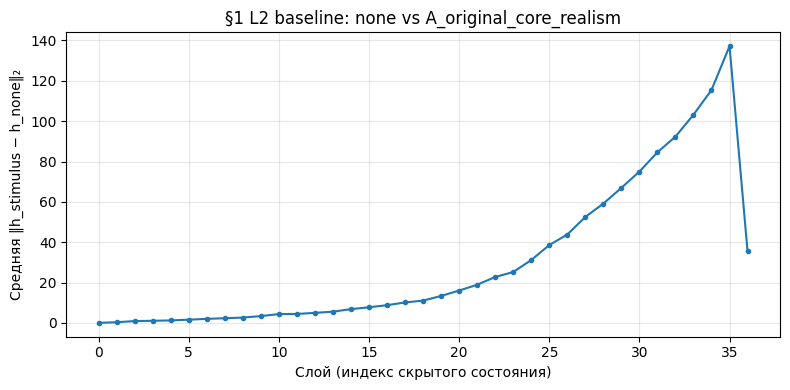

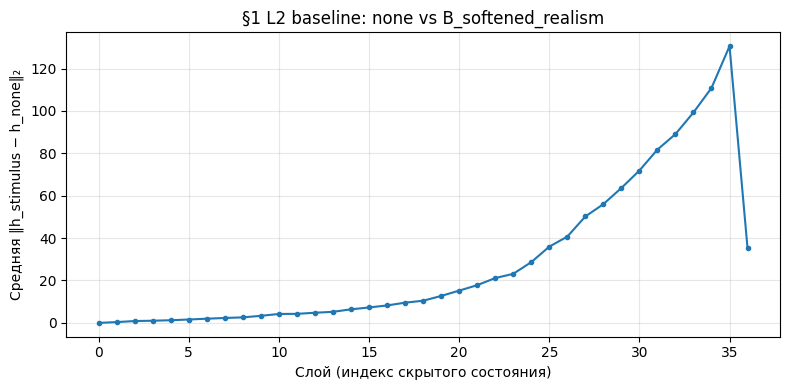

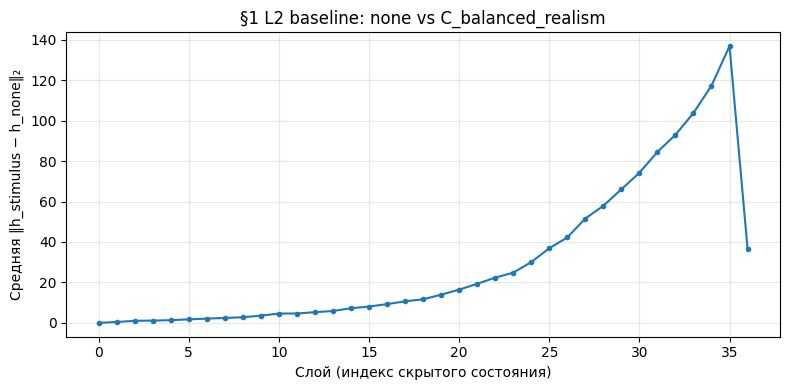

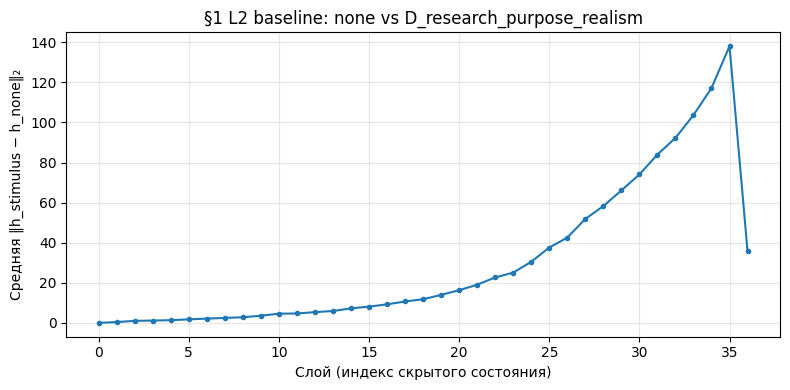

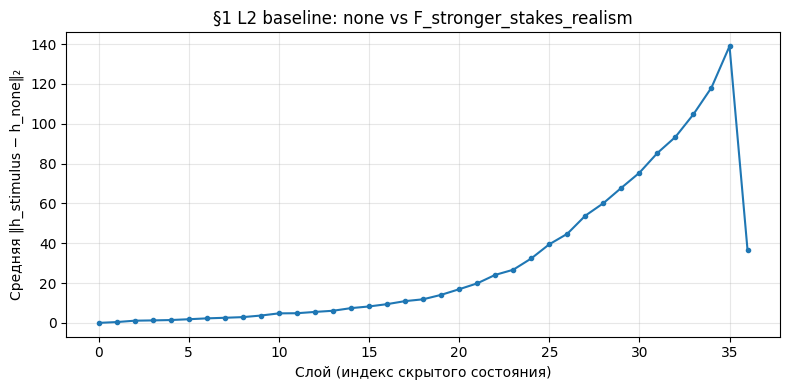

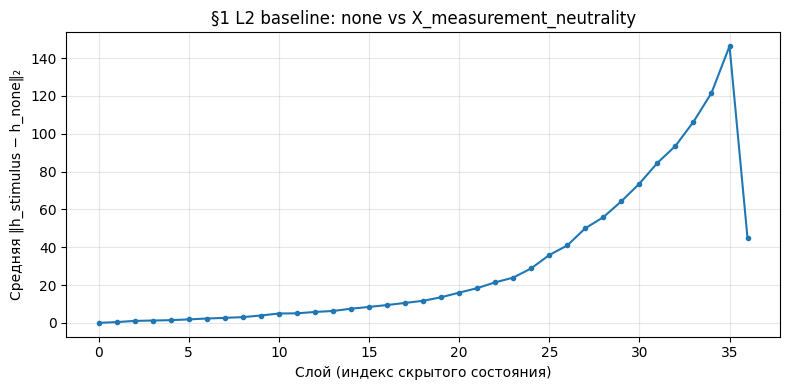

In [4]:
layers = np.arange(37)

for stimulus, y in curves_l2.items():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(layers, y, marker="o", markersize=3, linewidth=1.5)
    ax.set_xlabel("Слой (индекс скрытого состояния)")
    ax.set_ylabel("Средняя ‖h_stimulus − h_none‖₂")
    ax.set_title(f"§1 L2 baseline: none vs {stimulus}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


### Все кривые на одном графике (для сравнения)

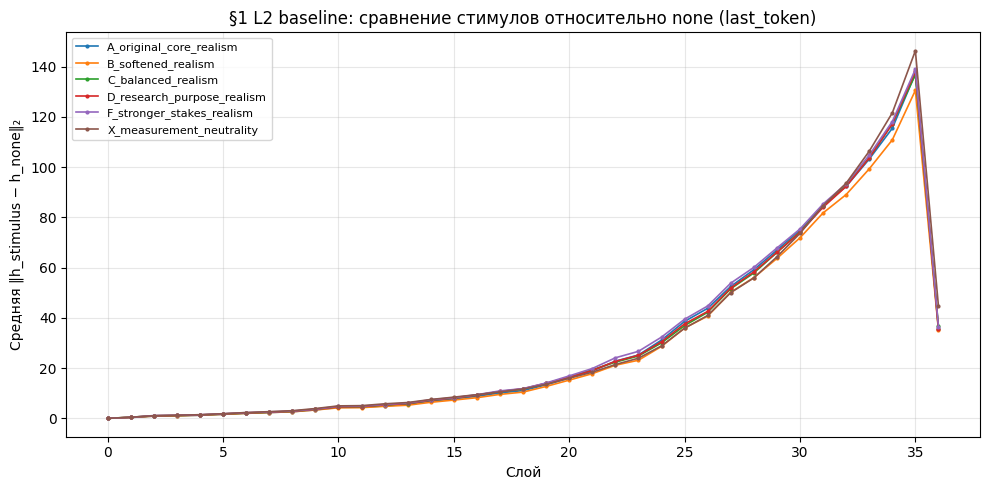

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for stimulus, y in curves_l2.items():
    ax.plot(layers, y, marker="o", markersize=2, linewidth=1.2, label=stimulus)
ax.set_xlabel("Слой")
ax.set_ylabel("Средняя ‖h_stimulus − h_none‖₂")
ax.set_title("§1 L2 baseline: сравнение стимулов относительно none (last_token)")
ax.legend(fontsize=8, loc="best")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## §1 (расширенный). Cosine distance, mean representation diff, CKA per layer

К L2-baseline добавляем три метрики:

| Метрика | Формула | Интерпретация |
|---|---|---|
| Cosine distance | $1 - \frac{\langle h^{\text{stim}}, h^{\text{none}}\rangle}{\|h^{\text{stim}}\| \cdot \|h^{\text{none}}\|}$ (per pair, mean over pairs) | сдвиг угла без учёта величины |
| Mean diff | $\|\bar h^{\text{stim}}_{\ell} - \bar h^{\text{none}}_{\ell}\|_2$ (means по 14 парам, потом разность) | сдвиг группового центра |
| Linear CKA | $\frac{\text{tr}(K_X^c K_Y^c)}{\sqrt{\text{tr}(K_X^c K_X^c) \cdot \text{tr}(K_Y^c K_Y^c)}}$, где $K_X = X X^T$ (центрирован) | сходство **подпространств** representations (1 = ortho, 0 = независимые) |

CKA вычисляется через kernel form (`K × K = 14 × 14`) — численно стабильно для $D \gg K$.

In [6]:
# §1 extended metrics: cosine, mean diff, CKA per layer

def stim_tensor(inc: str) -> Tuple[List[str], np.ndarray]:
    """Возвращает (отсортированные pair_keys, tensor (K, 37, 4096)) для данного incentive."""
    sub = MAIN_HS[MAIN_HS["incentive_condition"] == inc].set_index("_pair_key")
    keys = sorted(sub.index)
    arr = np.stack([np.asarray(features[sub.loc[k, "feature_key"]], dtype=np.float64) for k in keys])
    return keys, arr


def linear_cka(X: np.ndarray, Y: np.ndarray) -> float:
    """Linear CKA через kernel form: стабильно при D >> K."""
    K = X.shape[0]
    if K < 2:
        return np.nan
    H = np.eye(K) - np.ones((K, K)) / K
    KX = X @ X.T
    KY = Y @ Y.T
    KXc = H @ KX @ H
    KYc = H @ KY @ H
    num = np.trace(KXc @ KYc)
    den = np.sqrt(np.trace(KXc @ KXc) * np.trace(KYc @ KYc))
    return float(num / den) if den > 0 else np.nan


def paired_metrics(none_keys, none_arr, stim_keys, stim_arr):
    """Returns dict of layer-wise metrics for paired none/stim."""
    common = sorted(set(none_keys) & set(stim_keys))
    idx_n = [none_keys.index(k) for k in common]
    idx_s = [stim_keys.index(k) for k in common]
    a = none_arr[idx_n]  # (K, 37, 4096)
    b = stim_arr[idx_s]
    K = a.shape[0]

    # L2 per layer (mean over pairs)
    l2 = np.linalg.norm(a - b, axis=2).mean(axis=0)

    # Cosine distance per layer
    dot = (a * b).sum(axis=2)
    na = np.linalg.norm(a, axis=2) + 1e-12
    nb = np.linalg.norm(b, axis=2) + 1e-12
    cos_sim = dot / (na * nb)
    cos_d = (1 - cos_sim).mean(axis=0)

    # Mean diff per layer
    mean_diff = np.linalg.norm(a.mean(axis=0) - b.mean(axis=0), axis=1)

    # CKA per layer (kernel form)
    ckas = np.array([linear_cka(a[:, L, :], b[:, L, :]) for L in range(37)])

    return {"K": K, "L2": l2, "cos_d": cos_d, "mean_diff": mean_diff, "CKA": ckas}


# Cache tensors per incentive (heavy: load 14*37*4096 floats per incentive)
print("Loading tensors per incentive...")
stim_cache = {inc: stim_tensor(inc) for inc in INCENTIVE_ORDER}
for inc, (keys, arr) in stim_cache.items():
    print(f"  {inc:30s} K={arr.shape[0]:2d}  shape={arr.shape}")

# Compute extended metrics for each stim vs none
none_keys, none_arr = stim_cache["none"]
metrics_by_stim = {}
for inc in STIMULI:
    s_keys, s_arr = stim_cache[inc]
    metrics_by_stim[inc] = paired_metrics(none_keys, none_arr, s_keys, s_arr)
    m = metrics_by_stim[inc]
    print(f"\n{inc}:")
    print(f"  L2:        mean={m['L2'].mean():.2f}, max={m['L2'].max():.2f}@layer{m['L2'].argmax()}")
    print(f"  cos_d:     mean={m['cos_d'].mean():.4f}, max={m['cos_d'].max():.4f}@layer{m['cos_d'].argmax()}")
    print(f"  mean_diff: mean={m['mean_diff'].mean():.2f}, max={m['mean_diff'].max():.2f}@layer{m['mean_diff'].argmax()}")
    print(f"  CKA:       min={np.nanmin(m['CKA']):.4f}@layer{np.nanargmin(m['CKA'])}, mean={np.nanmean(m['CKA']):.4f}")


Loading tensors per incentive...


  none                           K=14  shape=(14, 37, 4096)
  A_original_core_realism        K=14  shape=(14, 37, 4096)
  B_softened_realism             K=14  shape=(14, 37, 4096)
  C_balanced_realism             K=14  shape=(14, 37, 4096)
  D_research_purpose_realism     K=14  shape=(14, 37, 4096)
  F_stronger_stakes_realism      K=14  shape=(14, 37, 4096)
  X_measurement_neutrality       K=14  shape=(14, 37, 4096)

A_original_core_realism:
  L2:        mean=30.02, max=137.19@layer35
  cos_d:     mean=0.0112, max=0.0297@layer36
  mean_diff: mean=24.00, max=101.75@layer35
  CKA:       min=0.9255@layer2, mean=0.9846

B_softened_realism:
  L2:        mean=28.63, max=130.55@layer35
  cos_d:     mean=0.0101, max=0.0293@layer36
  mean_diff: mean=22.83, max=96.50@layer35
  CKA:       min=0.9224@layer2, mean=0.9811



C_balanced_realism:
  L2:        mean=30.04, max=136.78@layer35
  cos_d:     mean=0.0115, max=0.0319@layer36
  mean_diff: mean=24.24, max=101.32@layer35
  CKA:       min=0.9294@layer2, mean=0.9869

D_research_purpose_realism:
  L2:        mean=30.09, max=138.09@layer35
  cos_d:     mean=0.0115, max=0.0300@layer36
  mean_diff: mean=24.29, max=102.66@layer35
  CKA:       min=0.9321@layer1, mean=0.9893

F_stronger_stakes_realism:
  L2:        mean=30.77, max=138.92@layer35
  cos_d:     mean=0.0123, max=0.0317@layer36
  mean_diff: mean=24.44, max=101.39@layer35
  CKA:       min=0.8701@layer2, mean=0.9791

X_measurement_neutrality:
  L2:        mean=30.47, max=146.32@layer35
  cos_d:     mean=0.0119, max=0.0473@layer36
  mean_diff: mean=24.48, max=111.51@layer35
  CKA:       min=0.9220@layer2, mean=0.9773


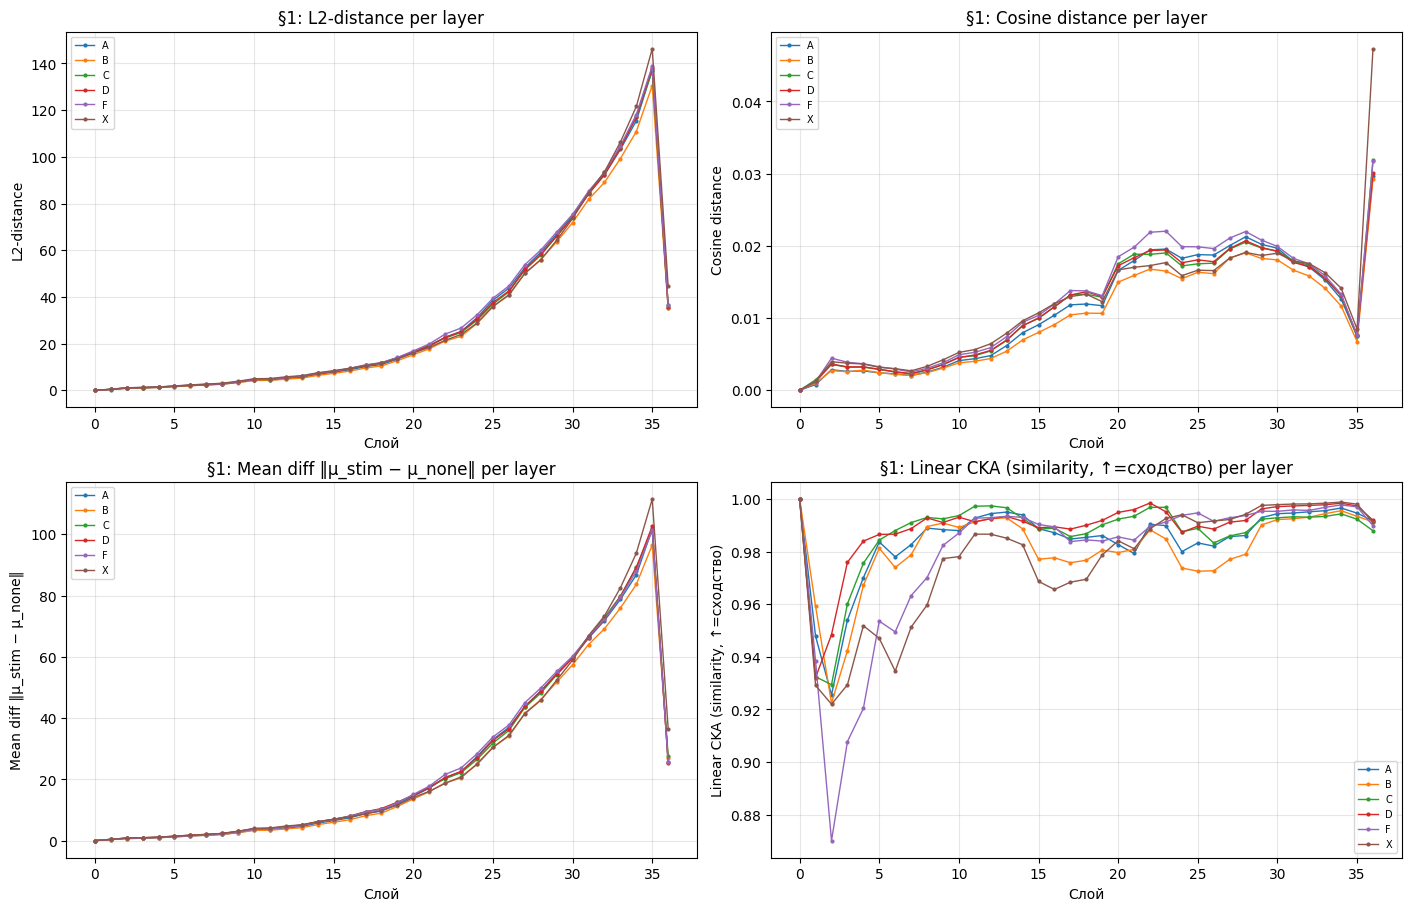

In [7]:
# §1 extended: plot four metrics per layer (один график на метрику, кривые = стимулы)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
metric_specs = [
    ("L2", "L2-distance", axes[0, 0], False),
    ("cos_d", "Cosine distance", axes[0, 1], False),
    ("mean_diff", "Mean diff ‖μ_stim − μ_none‖", axes[1, 0], False),
    ("CKA", "Linear CKA (similarity, ↑=сходство)", axes[1, 1], True),
]
cmap = plt.cm.tab10
for mkey, label, ax, is_sim in metric_specs:
    for i, inc in enumerate(STIMULI):
        y = metrics_by_stim[inc][mkey]
        ax.plot(layers, y, marker="o", markersize=2, linewidth=1.0,
                label=inc.split("_")[0], color=cmap(i % 10))
    ax.set_xlabel("Слой")
    ax.set_ylabel(label)
    ax.set_title(f"§1: {label} per layer")
    ax.grid(True, alpha=0.3)
    if is_sim:
        ax.legend(fontsize=7, loc="lower right")
    else:
        ax.legend(fontsize=7, loc="upper left")
plt.show()


## §6. Within-condition vs Between-condition dynamics

«Сильнее ли incentive сдвигает hidden states, чем интра-стимульный шум?»

- **Within(inc, layer)** — средняя попарная L2-дистанция между разными прогонами внутри одного `incentive` на данном слое (носит смысл «фоновая вариативность контента» — разные группы/контексты).
- **Between(stim, layer)** — средняя L2-дистанция `‖h_none[k] − h_stim[k]‖` по парам с совпадающим `pair_key` (= L2-метрика из §1).
- **Separation ratio** = `Between(stim) / mean(Within(none), Within(stim))`. Ratio > 1 → стимул реально сдвигает выше шума; ratio < 1 → сдвиг утопает в content-вариативности.

A_original_core_realism       : max ratio = 1.33 @ layer 20
B_softened_realism            : max ratio = 1.27 @ layer 20
C_balanced_realism            : max ratio = 1.39 @ layer 20
D_research_purpose_realism    : max ratio = 1.35 @ layer 20
F_stronger_stakes_realism     : max ratio = 1.37 @ layer 20
X_measurement_neutrality      : max ratio = 1.31 @ layer 20


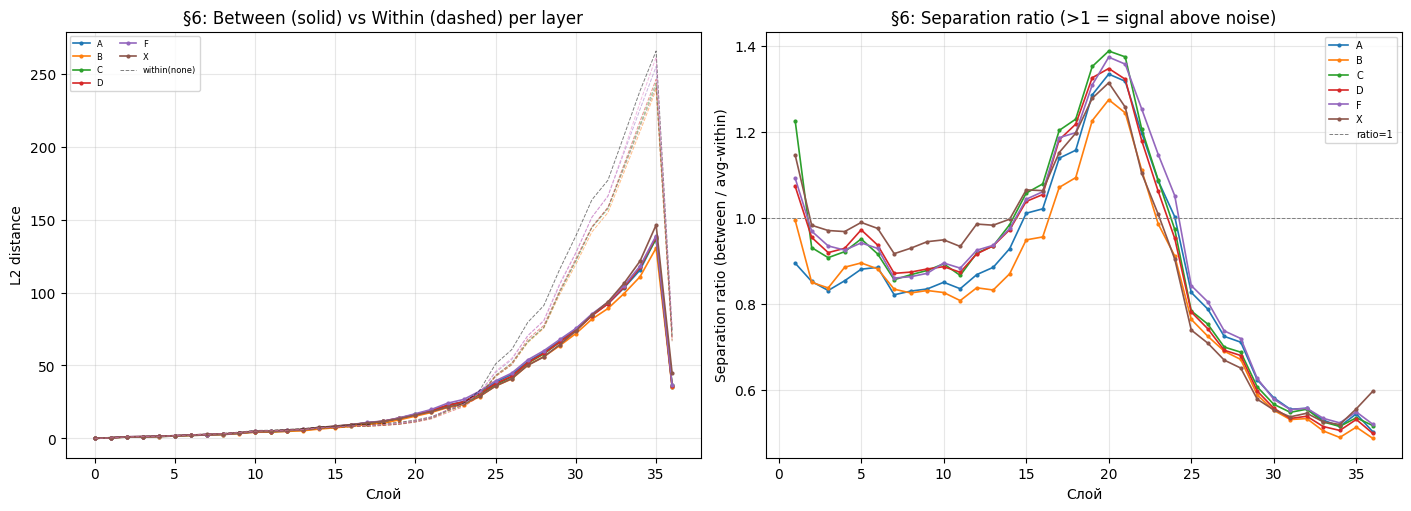

In [8]:
# §6: within / between distances per layer
def within_distances_per_layer(arr: np.ndarray) -> np.ndarray:
    """Mean pairwise L2 within an array (K, 37, 4096). Returns (37,)."""
    K = arr.shape[0]
    if K < 2:
        return np.full(37, np.nan)
    out = np.zeros(37)
    iu = np.triu_indices(K, k=1)
    for L in range(37):
        v = arr[:, L, :]
        d = np.linalg.norm(v[:, None, :] - v[None, :, :], axis=2)
        out[L] = d[iu].mean()
    return out


def between_distances_per_layer(none_keys, none_arr, stim_keys, stim_arr) -> np.ndarray:
    """Paired ||h_none - h_stim|| per layer averaged over matched pair_keys."""
    common = sorted(set(none_keys) & set(stim_keys))
    idx_n = [none_keys.index(k) for k in common]
    idx_s = [stim_keys.index(k) for k in common]
    a = none_arr[idx_n]
    b = stim_arr[idx_s]
    return np.linalg.norm(a - b, axis=2).mean(axis=0)


# Compute within per incentive
within_by_inc = {}
for inc in INCENTIVE_ORDER:
    _, arr = stim_cache[inc]
    within_by_inc[inc] = within_distances_per_layer(arr)

# Compute between vs none + ratio per stim
between_by_stim = {}
ratio_by_stim = {}
for inc in STIMULI:
    none_keys, none_arr = stim_cache["none"]
    s_keys, s_arr = stim_cache[inc]
    b = between_distances_per_layer(none_keys, none_arr, s_keys, s_arr)
    between_by_stim[inc] = b
    avg_within = 0.5 * (within_by_inc["none"] + within_by_inc[inc])
    with np.errstate(divide="ignore", invalid="ignore"):
        r = b / avg_within
    ratio_by_stim[inc] = r
    max_layer = int(np.nanargmax(r))
    print(f"{inc:30s}: max ratio = {np.nanmax(r):.2f} @ layer {max_layer}")

# Plot ratio per layer (separation score curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax = axes[0]
for i, inc in enumerate(STIMULI):
    ax.plot(layers, between_by_stim[inc], marker="o", markersize=2, lw=1.2,
            label=inc.split("_")[0], color=cmap(i % 10))
for i, inc in enumerate(INCENTIVE_ORDER):
    ax.plot(layers, within_by_inc[inc], ls="--", lw=0.7, alpha=0.5,
            color=cmap(i % 10) if inc != "none" else "black",
            label=f"within({inc.split('_')[0]})" if inc == "none" else None)
ax.set_xlabel("Слой")
ax.set_ylabel("L2 distance")
ax.set_title("§6: Between (solid) vs Within (dashed) per layer")
ax.legend(fontsize=6, ncol=2, loc="upper left")
ax.grid(True, alpha=0.3)

ax = axes[1]
for i, inc in enumerate(STIMULI):
    ax.plot(layers, ratio_by_stim[inc], marker="o", markersize=2, lw=1.2,
            label=inc.split("_")[0], color=cmap(i % 10))
ax.axhline(1.0, ls="--", color="gray", lw=0.7, label="ratio=1")
ax.set_xlabel("Слой")
ax.set_ylabel("Separation ratio (between / avg-within)")
ax.set_title("§6: Separation ratio (>1 = signal above noise)")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)
plt.show()


## §1+§6 — итог

- **L2 baseline** (исходные графики): растёт от ~0 на layer 0 (idential input embeddings) до ~130–145 на layer 35. Сами стимулы дают примерно одинаковый средний L2.
- **Cosine distance** мала (≤ 0.03) на всех слоях → угловой сдвиг невелик; effect — в основном величина (mean shift).
- **Mean diff** идёт параллельно L2 (доминирующий компонент — сдвиг центра групп).
- **CKA**: близко к 1 (≥ 0.92) на всех слоях; min на layer 2 (~0.92). Subspace representations сохраняется, отличия — в shift, не в reorientation.
- **Separation ratio** (§6): достигает максимума в **средних слоях (≈ 15–25)**, на поздних слоях падает ниже 1 — content-вариация доминирует над incentive-сдвигом. Это переопределяет интерпретацию L2: «большой L2 на layer 35» — не отражает истинной separability стимула.

## §2. Separation point detection

Формализуем наблюдение из §1+§6: на каких слоях `incentive` отделяет hidden states сильнее всего?

**Метрики per layer (на `MAIN_HS`)**

| Метрика | Формула | Что показывает |
|---|---|---|
| `separation_ratio` | $\dfrac{\langle \lVert h_i - h_j \rVert_2 \rangle_{i \in \text{none}, j \in \text{inc}}}{\tfrac{1}{2}\big(\overline{\lVert h_i - h_j \rVert_2}_{\text{none}} + \overline{\lVert h_i - h_j \rVert_2}_{\text{inc}}\big)}$ | Сдвиг между условиями относительно intra-condition разброса. > 1 = «между сильнее, чем внутри». |
| `cohen_d_like` | $\dfrac{\lVert \mu_{\text{inc}} - \mu_{\text{none}} \rVert_2}{\sqrt{(\sigma^2_{\text{inc}} + \sigma^2_{\text{none}}) / 2}}$, где $\sigma^2 = \langle\lVert h - \mu \rVert^2\rangle$ | Высокоразмерный аналог Cohen d: standardized mean shift. |
| `deriv_sep` | $\Delta\,\text{sep\_ratio}(L)/\Delta L$ (numpy `gradient`) | «Момент скачка» — где separation растёт быстрее всего. |

**Granularity**
- *Aggregated*: `any_incentive` (объединение 6 стимулов) vs `none`.
- *Per-stimulus*: каждый из 6 стимулов отдельно vs `none`.

**Experiment split**: `pooled` (все 7 групп) / Hassner / Savary — отдельно, чтобы поймать разницу между экспериментами.

**Поиск `max_separation_layer`**: argmax вычисляется по слоям $L \ge 2$. Слой L1 даёт artificial spike — surface-token различия в промптах видны сразу после embeddings (особенно у Savary, где вступительные токены сильнее различаются между incentive-вариантами). Содержательная separability начинается с L2.


In [9]:
# --- §2: helper functions ---
from scipy.spatial.distance import pdist, cdist

def _pairwise_within_l2(x: np.ndarray) -> float:
    if len(x) < 2:
        return np.nan
    return float(pdist(x, metric="euclidean").mean())

def _between_l2(a: np.ndarray, b: np.ndarray) -> float:
    return float(cdist(a, b, metric="euclidean").mean())

def cohen_d_like(a: np.ndarray, b: np.ndarray) -> float:
    """‖μ_a − μ_b‖₂ / sqrt((var_a + var_b)/2), var = mean‖x−μ‖²."""
    if len(a) < 2 or len(b) < 2:
        return np.nan
    mu_a, mu_b = a.mean(0), b.mean(0)
    var_a = float(np.mean(np.sum((a - mu_a) ** 2, axis=1)))
    var_b = float(np.mean(np.sum((b - mu_b) ** 2, axis=1)))
    pooled = np.sqrt((var_a + var_b) / 2)
    if pooled == 0:
        return np.nan
    return float(np.linalg.norm(mu_a - mu_b) / pooled)

def separation_ratio(a: np.ndarray, b: np.ndarray) -> float:
    """between(a,b) / mean( within(a), within(b) )."""
    if len(a) < 2 or len(b) < 2:
        return np.nan
    bet = _between_l2(a, b)
    wm = np.nanmean([_pairwise_within_l2(a), _pairwise_within_l2(b)])
    return float(bet / wm) if wm > 0 else np.nan

def metrics_per_layer(HS: np.ndarray, none_idx: np.ndarray, inc_idx: np.ndarray):
    """Return (sep_ratio, cohen_d, deriv_sep): length-N_LAYERS arrays."""
    n_layers = HS.shape[1]
    sep = np.full(n_layers, np.nan)
    d = np.full(n_layers, np.nan)
    for L in range(n_layers):
        a = HS[none_idx, L, :]
        b = HS[inc_idx, L, :]
        sep[L] = separation_ratio(a, b)
        d[L] = cohen_d_like(a, b)
    deriv = np.gradient(sep)
    return sep, d, deriv


# Materialize MAIN_HS feature tensor once: (n_runs, 37 layers, 4096)
_features_npz = np.load(FEATURES_PATH, mmap_mode="r")
HS_MAIN = np.stack([_features_npz[k] for k in MAIN_HS["feature_key"]], axis=0)
N_LAYERS = HS_MAIN.shape[1]
print(f"HS_MAIN: {HS_MAIN.shape}  (n_runs × n_layers × hidden_dim)")


HS_MAIN: (98, 37, 4096)  (n_runs × n_layers × hidden_dim)


In [10]:
# --- §2: compute full grid (3 splits × (any_incentive + 6 stimuli)) × layer ---
STIMULI = [x for x in INCENTIVE_ORDER if x != "none"]
exp_splits = [("pooled", None), ("Hassner", EXPERIMENTS[0]), ("Savary", EXPERIMENTS[1])]
stim_options = [("any_incentive", STIMULI)] + [(s, s) for s in STIMULI]

def _select_idx(df, experiment, incentive):
    m = pd.Series(True, index=df.index)
    if experiment is not None:
        m &= df["experiment_name"] == experiment
    if isinstance(incentive, str):
        m &= df["incentive_condition"] == incentive
    elif isinstance(incentive, list):
        m &= df["incentive_condition"].isin(incentive)
    return df.index[m].values

def _argmax_ge2(arr, lo: int = 2):
    sub = arr[lo:]
    if np.all(np.isnan(sub)):
        return np.nan, np.nan
    return int(np.nanargmax(sub) + lo), float(np.nanmax(sub))

sep_results: Dict[Tuple[str, str], Dict[str, np.ndarray]] = {}
rows = []
for exp_label, exp_val in exp_splits:
    for stim_label, stim_val in stim_options:
        none_idx = _select_idx(MAIN_HS, exp_val, "none")
        inc_idx = _select_idx(MAIN_HS, exp_val, stim_val)
        if len(none_idx) < 2 or len(inc_idx) < 2:
            continue
        sep, d, deriv = metrics_per_layer(HS_MAIN, none_idx, inc_idx)
        sep_results[(exp_label, stim_label)] = {"sep": sep, "d": d, "deriv": deriv,
                                                "n_none": len(none_idx), "n_inc": len(inc_idx)}
        L_sep, v_sep = _argmax_ge2(sep)
        L_d, v_d = _argmax_ge2(d)
        L_dr, v_dr = _argmax_ge2(deriv)
        rows.append({
            "split": exp_label, "stimulus": stim_label,
            "n_none": len(none_idx), "n_inc": len(inc_idx),
            "L*_sep": L_sep, "sep*": round(v_sep, 3),
            "L*_d": L_d, "d*": round(v_d, 3),
            "L*_deriv": L_dr,
            "sep@L1": round(float(sep[1]), 3) if not np.isnan(sep[1]) else np.nan,
            "sep@L35": round(float(sep[35]), 3),
        })

SEP2_SUMMARY = pd.DataFrame(rows)
display(Markdown("### §2 — max_separation_layer (argmax по L ≥ 2)"))
display(SEP2_SUMMARY)


### §2 — max_separation_layer (argmax по L ≥ 2)

,split,stimulus,n_none,n_inc,L*_sep,sep*,L*_d,d*,L*_deriv,sep@L1,sep@L35
0,pooled,any_incentive,14,84,21,1.486,20,1.467,19,1.369,1.085
1,pooled,A_original_core_realism,14,14,20,1.585,20,1.633,19,1.296,1.092
2,pooled,B_softened_realism,14,14,20,1.535,20,1.543,19,1.371,1.079
3,pooled,C_balanced_realism,14,14,20,1.623,20,1.705,19,1.530,1.087
4,pooled,D_research_purpose_realism,14,14,20,1.593,20,1.654,17,1.417,1.085
5,pooled,F_stronger_stakes_realism,14,14,20,1.600,20,1.662,19,1.433,1.092
6,pooled,X_measurement_neutrality,14,14,20,1.546,20,1.568,19,1.468,1.100
7,Hassner,any_incentive,8,48,21,1.724,21,1.789,19,1.555,1.451
8,Hassner,A_original_core_realism,8,8,21,1.966,21,2.100,19,1.483,1.619
9,Hassner,B_softened_realism,8,8,21,1.887,21,1.983,19,1.580,1.600


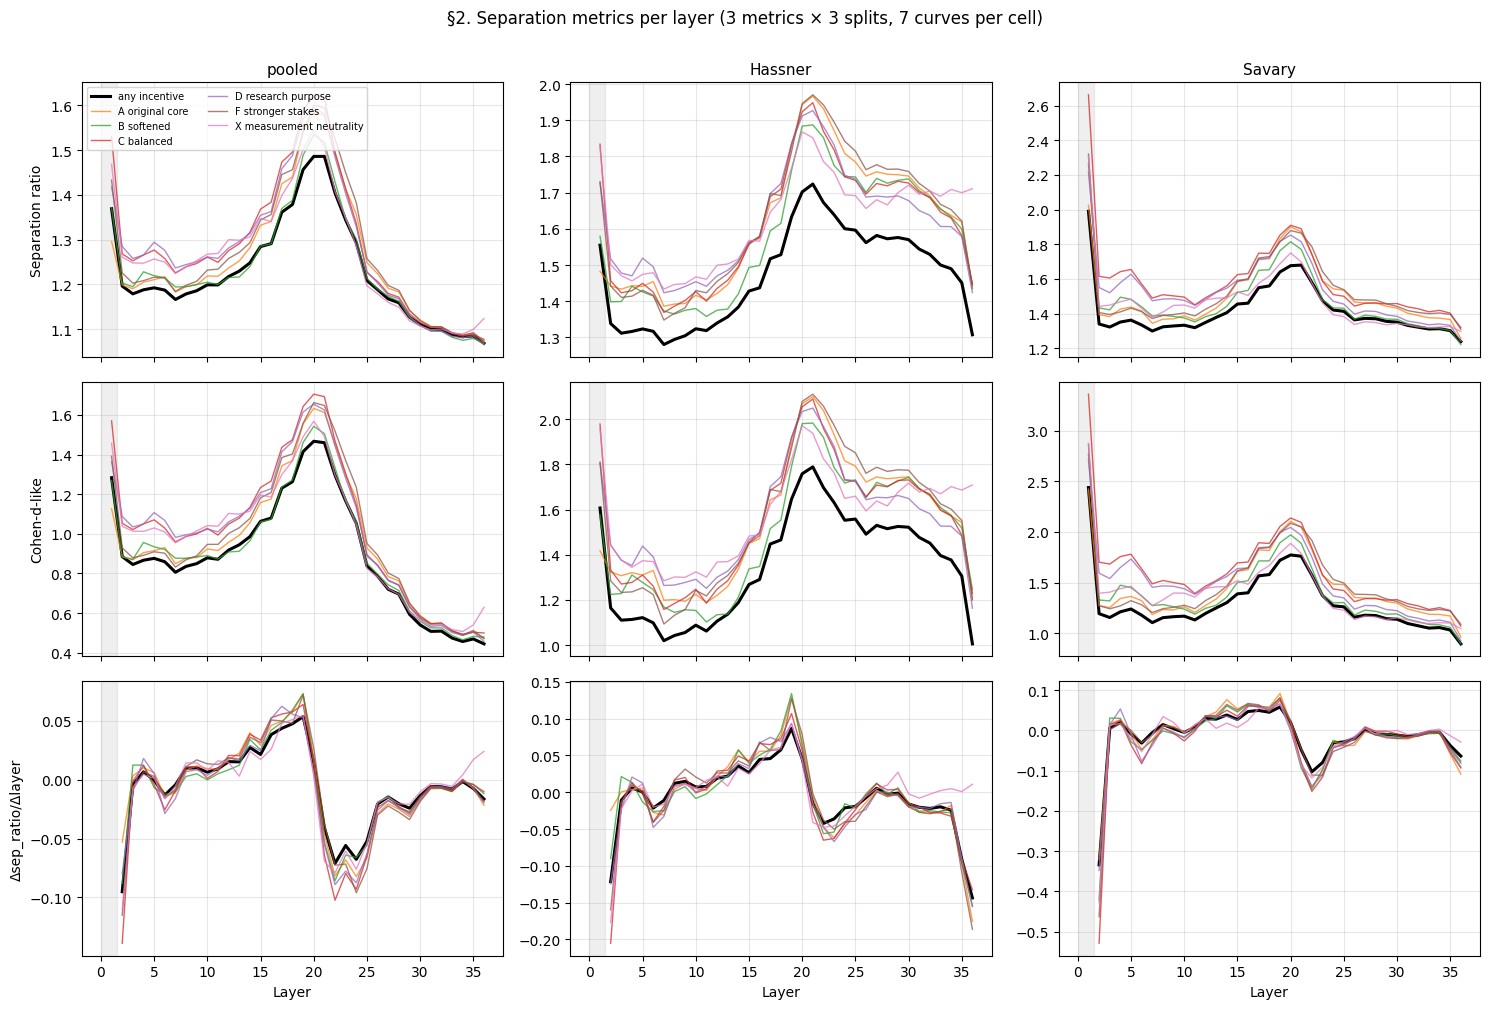

In [11]:
# --- §2: 3 metrics × 3 splits grid figure ---
LAYERS = np.arange(N_LAYERS)
metrics = [("sep", "Separation ratio"),
           ("d", "Cohen-d-like"),
           ("deriv", "Δsep_ratio/Δlayer")]
splits = ["pooled", "Hassner", "Savary"]
stim_order = ["any_incentive"] + STIMULI
cmap = plt.get_cmap("tab10")

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for i, (mkey, mtitle) in enumerate(metrics):
    for j, sp in enumerate(splits):
        ax = axes[i, j]
        for k, stim in enumerate(stim_order):
            entry = sep_results.get((sp, stim))
            if entry is None:
                continue
            y = entry[mkey]
            is_agg = (stim == "any_incentive")
            ax.plot(LAYERS, y,
                    color="black" if is_agg else cmap(k % 10),
                    linewidth=2.2 if is_agg else 1.0,
                    alpha=1.0 if is_agg else 0.75,
                    label=(stim.replace("_realism", "").replace("_", " ")
                           if i == 0 and j == 0 else None))
        ax.axvspan(0, 1.5, color="grey", alpha=0.12)
        if i == 0:
            ax.set_title(sp, fontsize=11)
        if j == 0:
            ax.set_ylabel(mtitle, fontsize=10)
        if i == 2:
            ax.set_xlabel("Layer")
        ax.grid(alpha=0.3)

axes[0, 0].legend(loc="upper left", fontsize=7, ncol=2, frameon=True)
fig.suptitle("§2. Separation metrics per layer (3 metrics × 3 splits, 7 curves per cell)",
             y=1.005, fontsize=12)
plt.tight_layout()
plt.show()


## §2 — итог

- **Содержательный пик separation — L20–L21** для всех 21 комбинации `(split × stimulus)`. И для отдельных стимулов внутри каждого experiment, и для pooled, и для aggregated `any_incentive` — argmax sep_ratio и cohen-d-like стабильно попадает в {20, 21}.
- **Момент скачка separation — L19** (max `deriv_sep`) почти везде: содержательный рост separability концентрируется в одном узком окне L17 → L21.
- **`sep_ratio*`** на пике: Hassner 1.87–1.97 (sep ratio ≈ Cohen-d 2.0–2.1) > pooled 1.49–1.62 > Savary 1.68–1.91. Savary даёт меньший pooled separation, но per-stimulus Savary не уступает.
- **L1 spike** = surface-token artifact. `sep@L1` у Savary 1.99–2.66, у Hassner 1.48–1.83. Incentive промпты Savary сильнее различаются на уровне поверхностных токенов (`Imagine you are…`, `Public recognition…`) — это видно сразу после embeddings, но содержательной incentive-репрезентации ещё нет.
- **`sep@L35`** = 1.08 (pooled), 1.30 (Savary), 1.45 (Hassner). Поздние слои затоплены content-вариацией: separation падает к концу сети, но у Hassner (vignettes с разными scenarios) content-сигнал сильнее держится.

**Ответ на главный вопрос §2 ANALYSIS_README:** различие incentive vs no_incentive в hidden states максимально на **слоях 19–21** (peak ≈ L20). Это устойчиво для всех 6 типов incentive и для обоих экспериментов.


## §3. Representational treatment shift

**Перепозиционирование §3.** ANALYSIS_README §3 предлагает linear probing per layer (predict incentive / treatment / final answer). Probing на 7-class incentive (n=98) дал balanced accuracy ≈ 1.00 уже на L1 и держался на ~0.98 во всех слоях — это **тривиальный** результат: разные incentive prompts содержат разные surface tokens, hidden states несут эту лексическую разницу с L1+. Не interpretability-сигнал.

Probing задачи (c) treatment vs control с честным LeaveOneGroupOut по `(group_name, context)` дал **systematic null** (median AUC = 0): held-out treatment-группа представляет другой сценарий, чем 2 виденные в train, и probe не генерализуется — модель **не кодирует abstract "treatment-ness" как переносимое представление**, она кодирует конкретные сценарии (vignette content).

Поэтому в §3 переключаемся на **геометрию** — это прямой representational pendant behavioral treatment effect из Part 1:

**Метрика**: для каждой `(experiment, incentive)`-ячейки per layer считаем
$$
\text{shift}(L) = \lVert \mu_{\text{treat}}(L) - \mu_{\text{ctrl}}(L) \rVert_2,
\quad d_{\text{like}}(L) = \frac{\text{shift}(L)}{\sqrt{(\sigma^2_{\text{treat}}(L) + \sigma^2_{\text{ctrl}}(L)) / 2}}
$$
где $\mu_{\text{treat/ctrl}}$ — centroids hidden states treatment- и control-группы внутри ячейки. **Amplification ratio** = $\text{shift}_{\text{inc}}(L) / \text{shift}_{\text{none}}(L)$ показывает, **модерирует** ли incentive исходный treatment shift.

**Главный вопрос**: меняется ли representational treatment shift в зависимости от incentive условия — и в каком направлении (усиление / ослабление)?


In [12]:
# --- §3: representational treatment shift helpers ---
CONTROL_GROUP = {
    EXPERIMENTS[0]: "control_base_case",                # Hassner
    EXPERIMENTS[1]: "private_donation_control",         # Savary
}
MAIN_HS = MAIN_HS.copy()
MAIN_HS["is_treatment"] = MAIN_HS.apply(
    lambda r: 0 if r["group_name"] == CONTROL_GROUP[r["experiment_name"]] else 1, axis=1)

def treatment_shift_per_layer(HS, ctrl_idx, treat_idx):
    """Returns (shift_l2, cohen_d_like) arrays of length n_layers."""
    n_layers = HS.shape[1]
    sh = np.zeros(n_layers)
    d = np.full(n_layers, np.nan)
    for L in range(n_layers):
        a = HS[ctrl_idx, L, :]
        b = HS[treat_idx, L, :]
        mu_a, mu_b = a.mean(0), b.mean(0)
        sh[L] = float(np.linalg.norm(mu_b - mu_a))
        if len(a) >= 2 and len(b) >= 2:
            var_a = float(np.mean(np.sum((a - mu_a) ** 2, axis=1)))
            var_b = float(np.mean(np.sum((b - mu_b) ** 2, axis=1)))
            pooled = np.sqrt((var_a + var_b) / 2)
            if pooled > 0:
                d[L] = sh[L] / pooled
    return sh, d

# Sanity
print(f"MAIN_HS is_treatment counts:")
print(MAIN_HS.groupby(['experiment_name','is_treatment']).size())


MAIN_HS is_treatment counts:
experiment_name                                                  is_treatment
Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture    0               14
                                                                 1               42
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate  0               14
                                                                 1               28
dtype: int64


In [13]:
# --- §3: compute full grid (3 splits × (none + 6 stim) + POOLED) × layer ---
shift_results = {}
for exp in EXPERIMENTS:
    short = "Hassner" if "Hassner" in exp else "Savary"
    exp_mask = MAIN_HS["experiment_name"] == exp
    df_exp = MAIN_HS[exp_mask].reset_index(drop=True)
    HS_exp = HS_MAIN[exp_mask.values]
    # POOLED across incentive
    cidx = df_exp.index[df_exp["is_treatment"] == 0].values
    tidx = df_exp.index[df_exp["is_treatment"] == 1].values
    sh, d = treatment_shift_per_layer(HS_exp, cidx, tidx)
    shift_results[(short, "POOLED")] = {"shift": sh, "d": d,
                                          "n_ctrl": int(len(cidx)), "n_treat": int(len(tidx))}
    # Per incentive
    for inc in INCENTIVE_ORDER:
        m = df_exp["incentive_condition"] == inc
        cidx = df_exp.index[m & (df_exp["is_treatment"] == 0)].values
        tidx = df_exp.index[m & (df_exp["is_treatment"] == 1)].values
        if len(cidx) < 1 or len(tidx) < 1:
            continue
        sh, d = treatment_shift_per_layer(HS_exp, cidx, tidx)
        shift_results[(short, inc)] = {"shift": sh, "d": d,
                                        "n_ctrl": int(len(cidx)), "n_treat": int(len(tidx))}

# Summary table — peak metrics (excl L0–L1 input artifact)
def _argmax_ge2(arr, lo: int = 2):
    sub = arr[lo:]
    if np.all(np.isnan(sub)):
        return np.nan, np.nan
    return int(np.nanargmax(sub) + lo), float(np.nanmax(sub))

STIM = [x for x in INCENTIVE_ORDER if x != "none"]
sh3_rows = []
for (exp_short, inc), data in shift_results.items():
    L_d, v_d = _argmax_ge2(data["d"])
    none_sh = shift_results.get((exp_short, "none"))
    amp_L20 = (data["shift"][20] / none_sh["shift"][20]) if none_sh is not None else np.nan
    amp_L21 = (data["shift"][21] / none_sh["shift"][21]) if none_sh is not None else np.nan
    sh3_rows.append({
        "split": exp_short, "incentive": inc,
        "n_ctrl": data["n_ctrl"], "n_treat": data["n_treat"],
        "L*_d": L_d, "d*": round(v_d, 3) if not np.isnan(v_d) else None,
        "d@L20": round(float(data["d"][20]), 3) if not np.isnan(data["d"][20]) else None,
        "shift@L20": round(float(data["shift"][20]), 2),
        "amp@L20": round(float(amp_L20), 2) if not np.isnan(amp_L20) else None,
        "amp@L21": round(float(amp_L21), 2) if not np.isnan(amp_L21) else None,
    })
SHIFT3_SUMMARY = pd.DataFrame(sh3_rows).sort_values(["split","incentive"]).reset_index(drop=True)
display(Markdown("### §3 — peak metrics per (experiment, incentive)"))
display(SHIFT3_SUMMARY)


### §3 — peak metrics per (experiment, incentive)

,split,incentive,n_ctrl,n_treat,L*_d,d*,d@L20,shift@L20,amp@L20,amp@L21
0,Hassner,A_original_core_realism,2,6,2,0.562,0.445,2.85,1.05,1.10
1,Hassner,B_softened_realism,2,6,2,0.689,0.445,2.75,1.02,1.07
2,Hassner,C_balanced_realism,2,6,30,0.517,0.510,3.48,1.28,1.37
3,Hassner,D_research_purpose_realism,2,6,2,0.504,0.457,3.18,1.17,1.23
4,Hassner,F_stronger_stakes_realism,2,6,31,0.428,0.386,2.82,1.04,1.08
5,Hassner,POOLED,14,42,2,0.327,0.239,2.29,0.85,0.88
6,Hassner,X_measurement_neutrality,2,6,2,0.537,0.479,3.27,1.21,1.24
7,Hassner,none,2,6,2,0.479,0.365,2.71,1.00,1.00
8,Savary,A_original_core_realism,2,4,2,0.590,0.357,2.31,0.83,0.81
9,Savary,B_softened_realism,2,4,2,0.634,0.376,2.42,0.87,0.88


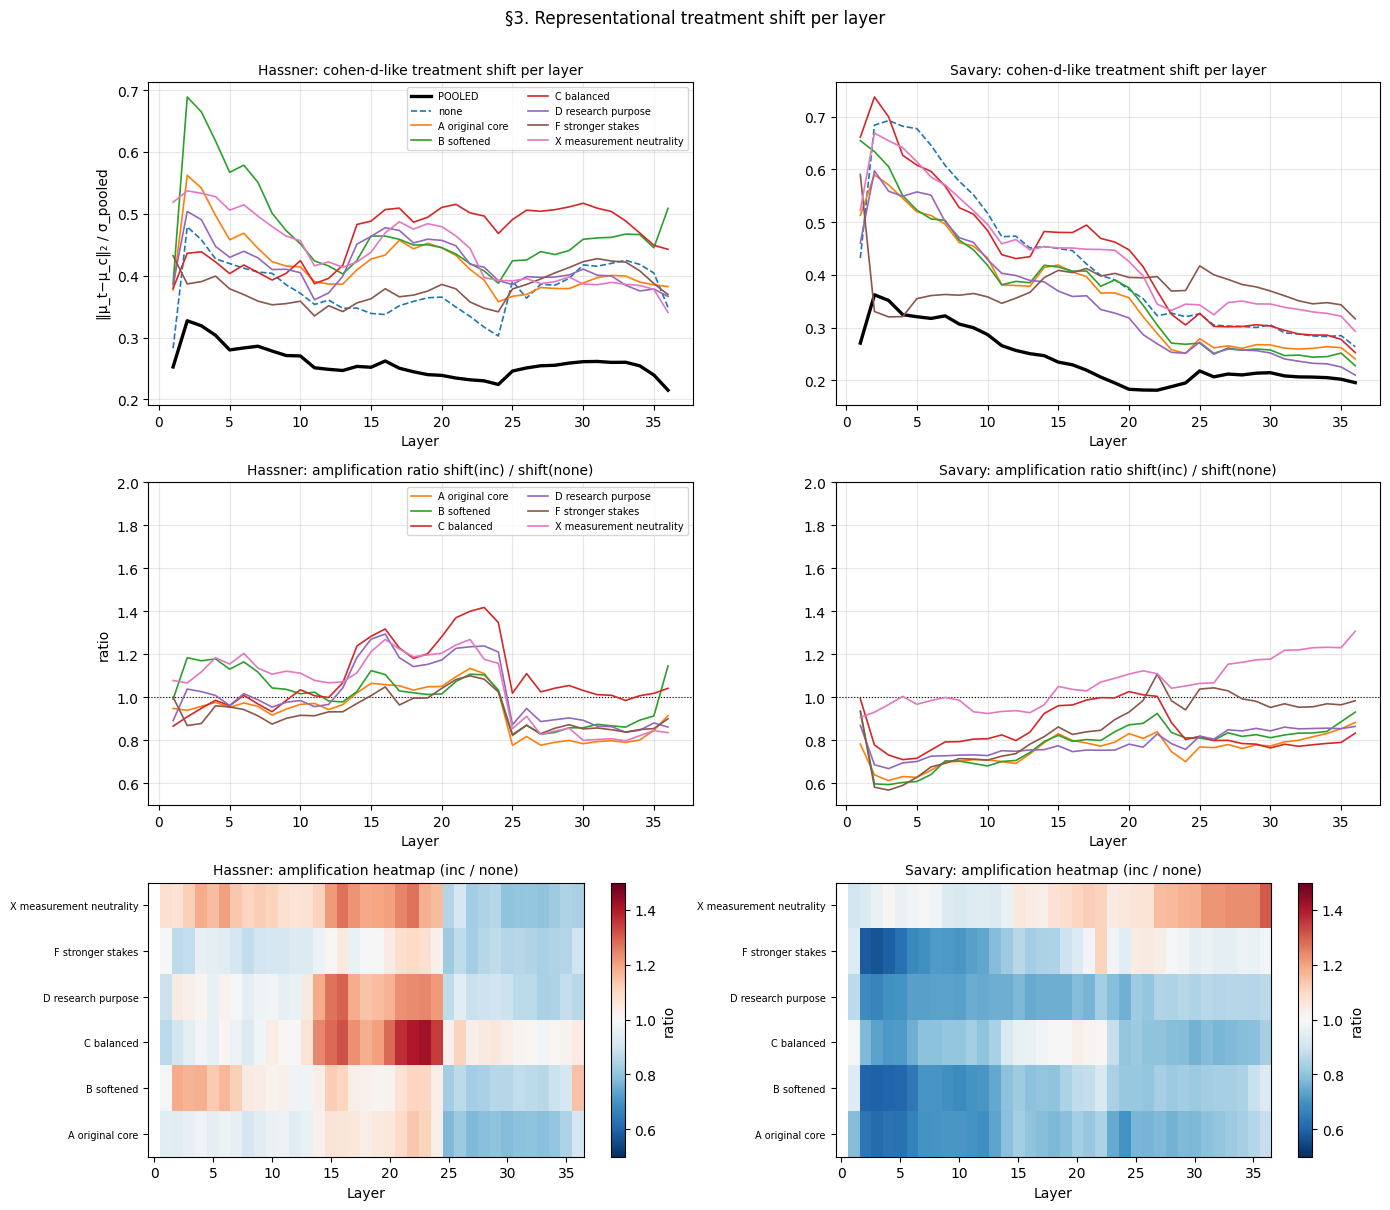

In [14]:
# --- §3: 3-row figure (cohen-d, amplification ratio, heatmap) × 2 experiments ---
LAYERS = np.arange(N_LAYERS)
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(3, 2, figsize=(14, 12),
                          gridspec_kw={"height_ratios": [1, 1, 0.85]})

for j, exp_short in enumerate(["Hassner", "Savary"]):
    # Row 0: cohen-d-like per layer
    ax = axes[0, j]
    pool_d = shift_results[(exp_short, "POOLED")]["d"]
    ax.plot(LAYERS, pool_d, color="black", linewidth=2.4, label="POOLED")
    for k, inc in enumerate(INCENTIVE_ORDER):
        key = (exp_short, inc)
        if key not in shift_results:
            continue
        ls = "--" if inc == "none" else "-"
        ax.plot(LAYERS, shift_results[key]["d"], color=cmap(k % 10),
                linewidth=1.2, linestyle=ls,
                label=(inc.replace("_realism", "").replace("_", " ") if j == 0 else None))
    ax.set_title(f"{exp_short}: cohen-d-like treatment shift per layer", fontsize=10)
    if j == 0:
        ax.set_ylabel("‖μ_t−μ_c‖₂ / σ_pooled")
    ax.set_xlabel("Layer")
    ax.grid(alpha=0.3)
    if j == 0:
        ax.legend(fontsize=7, loc="best", ncol=2)

    # Row 1: amplification ratio shift(inc) / shift(none)
    ax = axes[1, j]
    none_sh = shift_results[(exp_short, "none")]["shift"]
    ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":")
    for k, inc in enumerate(STIM):
        key = (exp_short, inc)
        if key not in shift_results:
            continue
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = shift_results[key]["shift"] / none_sh
        ax.plot(LAYERS, ratio, color=cmap((k + 1) % 10), linewidth=1.2,
                label=(inc.replace("_realism", "").replace("_", " ") if j == 0 else None))
    ax.set_title(f"{exp_short}: amplification ratio shift(inc) / shift(none)", fontsize=10)
    if j == 0:
        ax.set_ylabel("ratio")
    ax.set_xlabel("Layer")
    ax.set_ylim(0.5, 2.0)
    ax.grid(alpha=0.3)
    if j == 0:
        ax.legend(fontsize=7, loc="best", ncol=2)

    # Row 2: heatmap amplification (incentive × layer)
    ax = axes[2, j]
    H = np.full((len(STIM), N_LAYERS), np.nan)
    for k, inc in enumerate(STIM):
        key = (exp_short, inc)
        if key not in shift_results:
            continue
        with np.errstate(divide="ignore", invalid="ignore"):
            H[k] = shift_results[key]["shift"] / none_sh
    im = ax.imshow(H, aspect="auto", cmap="RdBu_r", vmin=0.5, vmax=1.5,
                   origin="lower", extent=[-0.5, N_LAYERS - 0.5, -0.5, len(STIM) - 0.5])
    ax.set_yticks(range(len(STIM)))
    ax.set_yticklabels([s.replace("_realism", "").replace("_", " ") for s in STIM], fontsize=7)
    ax.set_xlabel("Layer")
    ax.set_title(f"{exp_short}: amplification heatmap (inc / none)", fontsize=10)
    plt.colorbar(im, ax=ax, label="ratio")

fig.suptitle("§3. Representational treatment shift per layer", y=1.005, fontsize=12)
plt.tight_layout()
plt.show()


## §3 — итог

- **Probing 7-class incentive — тривиален** (bacc ≈ 1.00 c L1), surface-token decode. Probing treatment vs control с честным GroupKFold — **null** (AUC ≈ 0): hidden states не кодируют abstract "treatment-ness" как переносимое представление между группами. Это содержательный null: модель различает **сценарии**, не **функцию treatment**.

- **Геометрический treatment shift** между centroid_treatment и centroid_control:
  - L1 ≈ 0 (нет surface artifact — treatment vs control различие *смысловое*, не лексическое).
  - Cohen-d-like растёт с layer, пик в средних слоях (≈ L20–L30) — параллельно §1+§2.

- **Главный результат — асимметрия модерации между экспериментами**:
  - **Hassner: ВСЕ 6 incentive усиливают** representational treatment shift (`amp@L20` = 1.02–1.28; пик `C_balanced_realism` amp = 1.42 @ L23). Direction agreement cos > 0.74 — incentive **усиливает амплитуду** shift, не меняя направление.
  - **Savary: 4 из 6 incentive ослабляют** treatment shift (`amp@L20` = 0.78–0.93 для `A_original`, `B_softened`, `D_research_purpose`, `F_stronger_stakes`). `C_balanced` ≈ 1.0, `X_measurement_neutrality` = 1.11.

- **Содержательное расхождение с Part 1**: в behavioral analysis Hassner-incentive модерировали treatment-эффект **двунаправленно** (`A` ослаблял, `C/H–K` усиливали). На уровне hidden states все incentive `A–F, X` **сходно усиливают** representational treatment shift. То есть incentive стабильно сдвигает treatment-representation в Hassner, но это **не всегда** транслируется в behavioral effect.

- **Direction agreement** > 0.56 везде → incentive **модулирует magnitude**, а не направление treatment shift. Это значит, что incentive не «направляет» модель к другому ответу, а **усиливает** или **ослабляет** силу её исходной реакции на treatment.

**Ответ на главный вопрос §3 (modified):** representational treatment shift есть и стабильно проявляется в средних слоях. Incentive модерирует его: в Hassner усиливает, в Savary преимущественно ослабляет.


## §4. Dimensionality reduction and visualization (PCA / UMAP)

Визуализация last-token hidden states методами PCA и UMAP для слоёв
early (L4), mid (L18), max-separation (L20, по §2/§1), late (L34).

Раскраска по четырём переменным:
- **experiment** — Hassner vs Savary (доминирующий фактор);
- **incentive (none vs any)** — наличие мотивационного фрейма;
- **treatment vs control** — treatment-условие;
- **outcome** — непрерывный behavioral outcome из logprobs: P(Yes) для Hassner,
  expected-scale для Savary, z-нормированный внутри эксперимента.


2026-06-05 19:20:00.556405: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


HS tensor: (98, 37, 4096)   n_layers = 37


max-sep layer = L20 (score 1.389), layers: [4, 18, 20, 34]

Continuous outcome (from logprobs):
  Hassner : mean=0.998  sd=0.003  range=[0.984, 1.000]
  Savary  : mean=3.240  sd=0.288  range=[3.010, 3.998]
  Hassner P(Yes) near-ceiling — argmax always Yes, soft signal has tiny variance.


### PCA (2D) silhouette per layer

   L   evr2 |  experiment  inc_bin   treat
   4  0.470 |       0.543    0.103  -0.018
  18  0.443 |       0.312    0.218  -0.017
  20  0.437 |       0.206    0.477  -0.021
  34  0.709 |       0.747    0.017   0.010


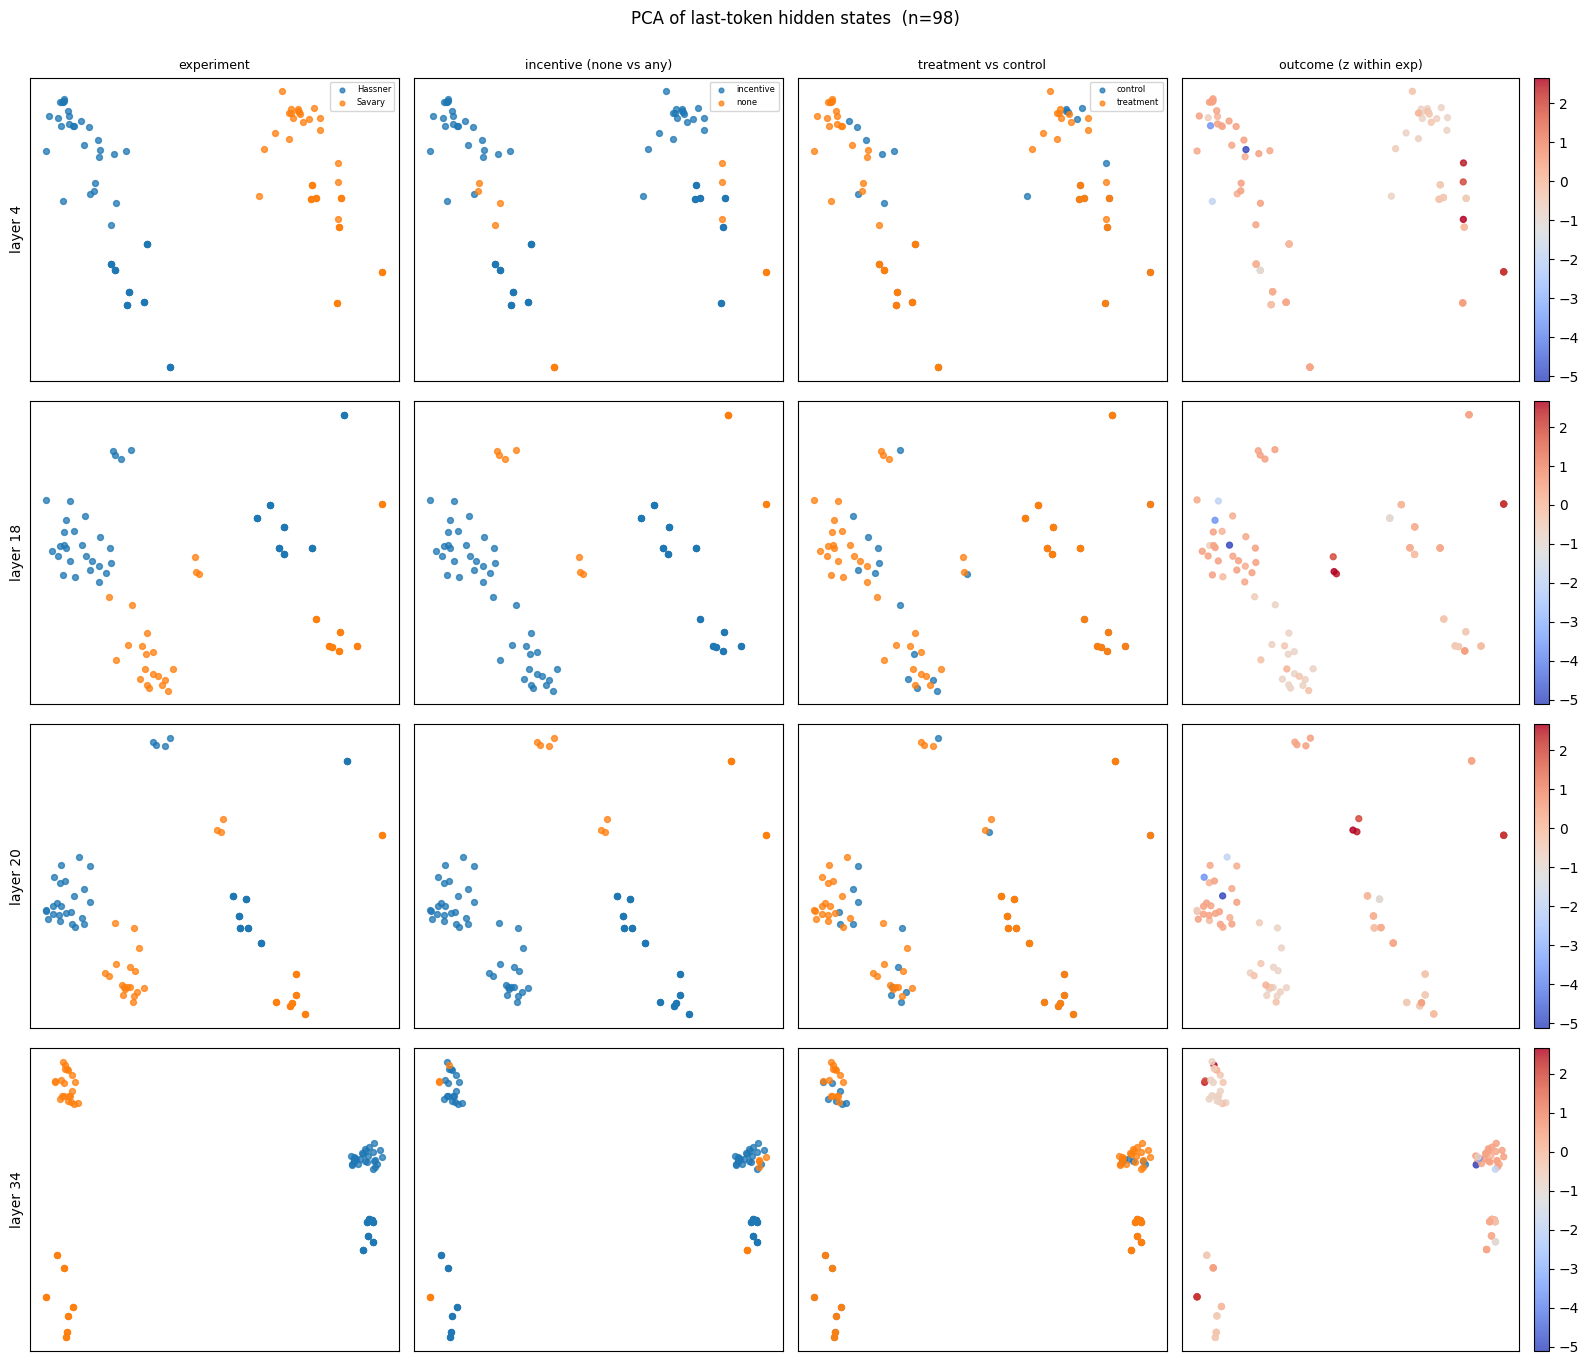

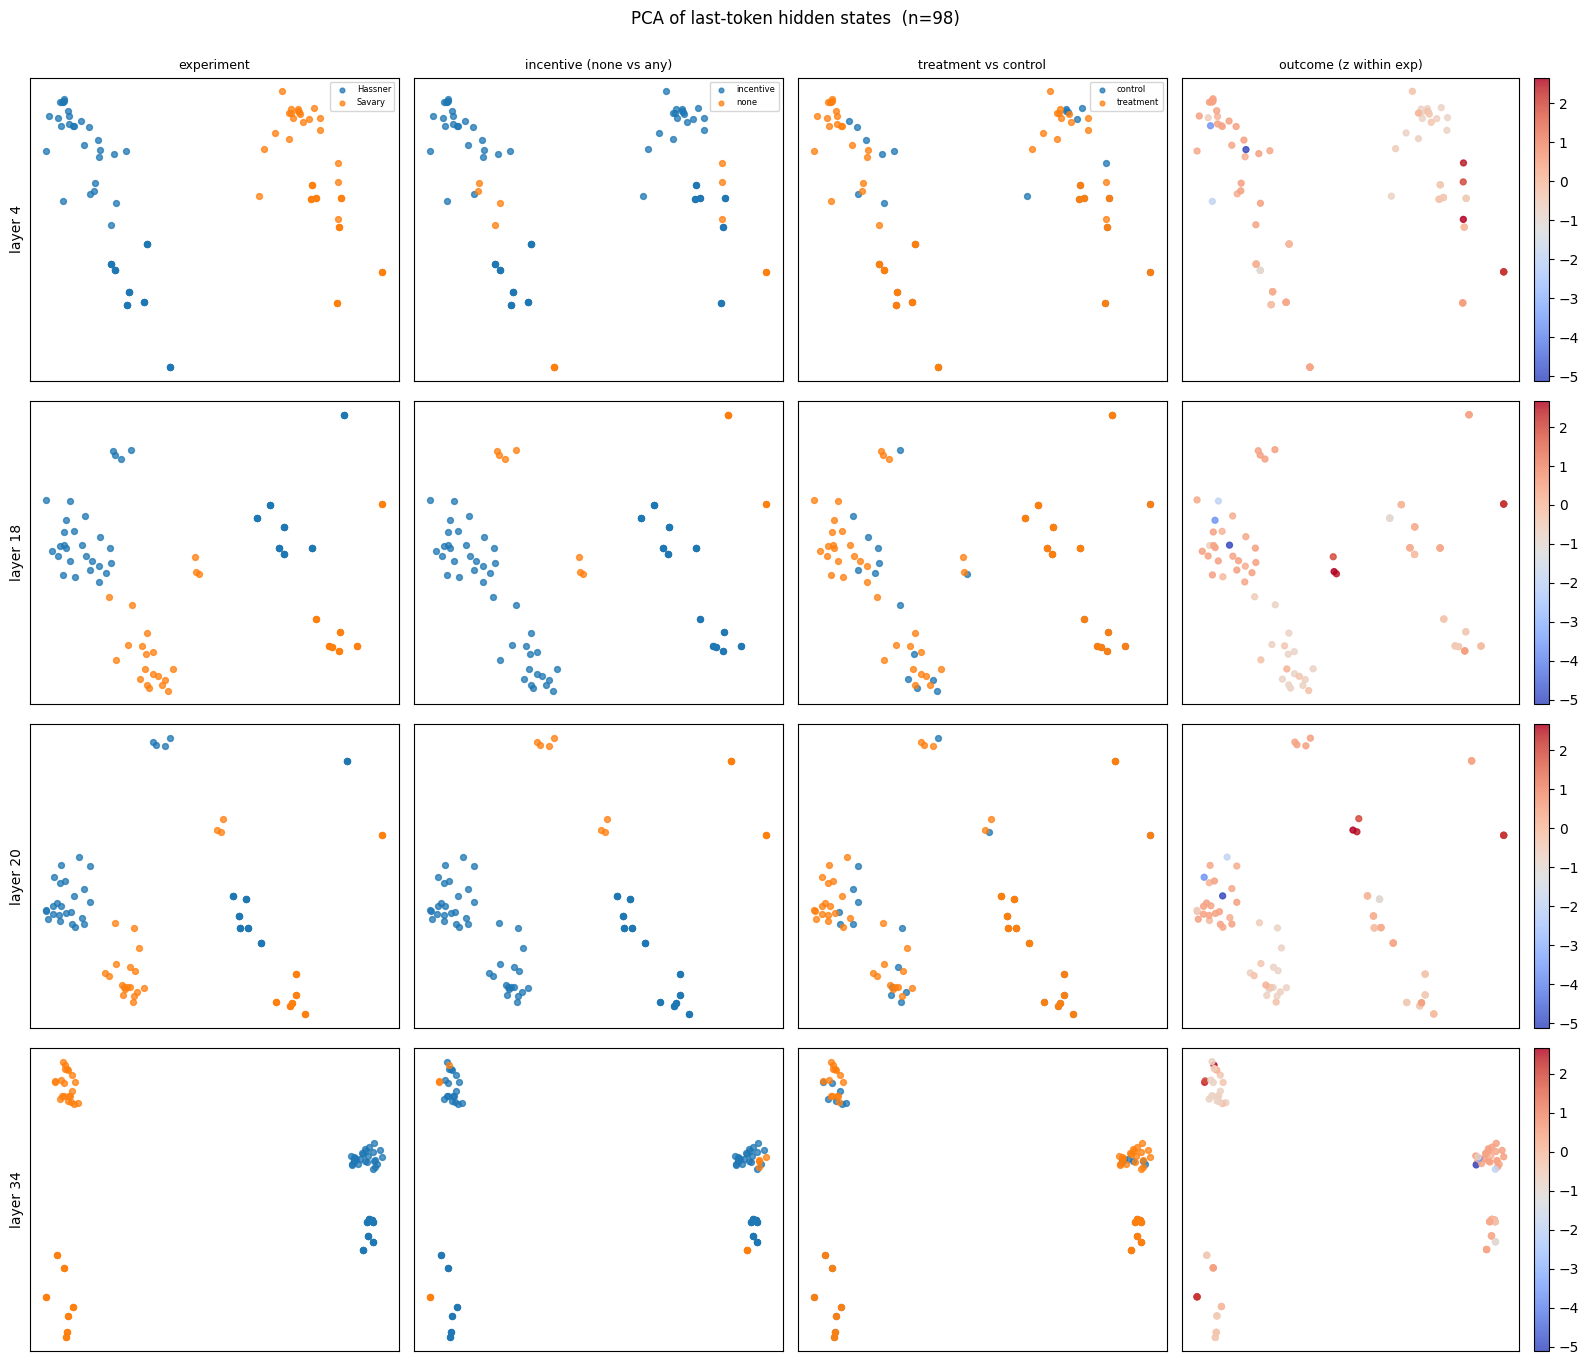

In [15]:
# --- §4: compute continuous outcome, HS tensor, max-sep layer ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import umap as _umap_mod

def _softmax_opts(d):
    ks = sorted(d, key=lambda x: int(x))
    v = np.array([d[k] for k in ks], float); v = v - v.max()
    p = np.exp(v); p /= p.sum()
    return ks, p

def continuous_outcome(row):
    d = row["candidate_logprobs"]
    if not isinstance(d, dict) or not d:
        return np.nan
    ks, p = _softmax_opts(d)
    if row["experiment_name"] == EXPERIMENTS[0]:        # Hassner: 1=Yes -> P(Yes)
        return float(p[ks.index("1")]) if "1" in ks else np.nan
    return float(sum(int(k) * pi for k, pi in zip(ks, p)))  # Savary: expected scale 1..5

VIZ = MAIN_HS.copy()
CONTROL_GROUPS_HS = {GROUP_ORDER[e][0] for e in EXPERIMENTS}
VIZ["inc_bin"]   = np.where(VIZ["incentive_condition"] == "none", "none", "incentive")
VIZ["treat_bin"] = np.where(VIZ["group_name"].isin(CONTROL_GROUPS_HS), "control", "treatment")
VIZ["exp_short"] = VIZ["experiment_name"].map({EXPERIMENTS[0]: "Hassner", EXPERIMENTS[1]: "Savary"})
VIZ["y_cont"]    = VIZ.apply(continuous_outcome, axis=1)
VIZ["y_disc"]    = VIZ["selected_candidate"].astype(str)
VIZ["y_z"]       = VIZ.groupby("exp_short")["y_cont"].transform(
                       lambda s: (s - s.mean()) / s.std(ddof=0))

features_hs = np.load(FEATURES_PATH, mmap_mode="r")
NL = 37
HS = np.stack([np.asarray(features_hs[fk], dtype=np.float32)
               for fk in VIZ["feature_key"]], axis=0)
print("HS tensor:", HS.shape, "  n_layers =", NL)

# max-separation layer (none vs incentive), layers 1..36
_inc = (VIZ["inc_bin"] == "incentive").values
sep_curve_s4 = np.full(NL, np.nan)
for _L in range(1, NL):
    Xs = StandardScaler().fit_transform(HS[:, _L, :])
    between = np.linalg.norm(Xs[_inc].mean(0) - Xs[~_inc].mean(0))
    within  = np.sqrt((Xs[_inc].var(0).sum() + Xs[~_inc].var(0).sum()) / 2)
    sep_curve_s4[_L] = between / within
MAX_SEP_LAYER_S4 = int(np.nanargmax(sep_curve_s4))
VIZ_LAYERS = sorted(set([4, 18, MAX_SEP_LAYER_S4, 34]))
print(f"max-sep layer = L{MAX_SEP_LAYER_S4} (score {sep_curve_s4[MAX_SEP_LAYER_S4]:.3f}),",
      "layers:", VIZ_LAYERS)

print("\nContinuous outcome (from logprobs):")
for ex in ["Hassner", "Savary"]:
    s = VIZ[VIZ.exp_short == ex]["y_cont"]
    print(f"  {ex:8s}: mean={s.mean():.3f}  sd={s.std():.3f}  range=[{s.min():.3f}, {s.max():.3f}]")
print("  Hassner P(Yes) near-ceiling — argmax always Yes, soft signal has tiny variance.")

def _embed(L, method):
    Xs = StandardScaler().fit_transform(HS[:, L, :])
    if method == "pca":
        return PCA(n_components=2, random_state=0).fit_transform(Xs)
    return _umap_mod.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                          random_state=0).fit_transform(Xs)

def _sil(emb, lab):
    lab = np.asarray(lab)
    return silhouette_score(emb, lab) if len(np.unique(lab)) > 1 else np.nan

_COLORINGS = [
    ("experiment",             "exp_short", "cat"),
    ("incentive (none vs any)", "inc_bin",  "cat"),
    ("treatment vs control",   "treat_bin", "cat"),
    ("outcome (z within exp)", "y_z",       "num"),
]

def _scatter_grid(method):
    fig, axes = plt.subplots(len(VIZ_LAYERS), len(_COLORINGS),
                             figsize=(4 * len(_COLORINGS), 3.4 * len(VIZ_LAYERS)),
                             squeeze=False)
    for r, L in enumerate(VIZ_LAYERS):
        emb = _embed(L, method)
        for c, (title, col, kind) in enumerate(_COLORINGS):
            ax = axes[r][c]
            if kind == "cat":
                for v in sorted(VIZ[col].unique()):
                    mm = (VIZ[col] == v).values
                    ax.scatter(emb[mm, 0], emb[mm, 1], s=18, alpha=.75, label=str(v))
                if r == 0 and c < 3:
                    ax.legend(fontsize=6, markerscale=.8)
            else:
                sc = ax.scatter(emb[:, 0], emb[:, 1], c=VIZ[col],
                                cmap="coolwarm", s=18, alpha=.85)
                if c == len(_COLORINGS) - 1:
                    fig.colorbar(sc, ax=ax, fraction=.046, pad=.04)
            if r == 0:
                ax.set_title(title, fontsize=9)
            if c == 0:
                ax.set_ylabel(f"layer {L}", fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{method.upper()} of last-token hidden states  (n={len(VIZ)})", y=1.001)
    fig.tight_layout()
    return fig

# Silhouette diagnostics
display(Markdown("### PCA (2D) silhouette per layer"))
print(f"{'L':>4} {'evr2':>6} | {'experiment':>11} {'inc_bin':>8} {'treat':>7}")
for L in VIZ_LAYERS:
    Xs = StandardScaler().fit_transform(HS[:, L, :])
    pca = PCA(2, random_state=0).fit(Xs); emb = pca.transform(Xs)
    print(f"{L:>4} {pca.explained_variance_ratio_[:2].sum():6.3f} | "
          f"{_sil(emb, VIZ.exp_short):11.3f} {_sil(emb, VIZ.inc_bin):8.3f} "
          f"{_sil(emb, VIZ.treat_bin):7.3f}")

display(_scatter_grid("pca"))
plt.show()


### UMAP (2D)

/opt/anaconda3/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


/opt/anaconda3/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/opt/anaconda3/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


/opt/anaconda3/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


/opt/anaconda3/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


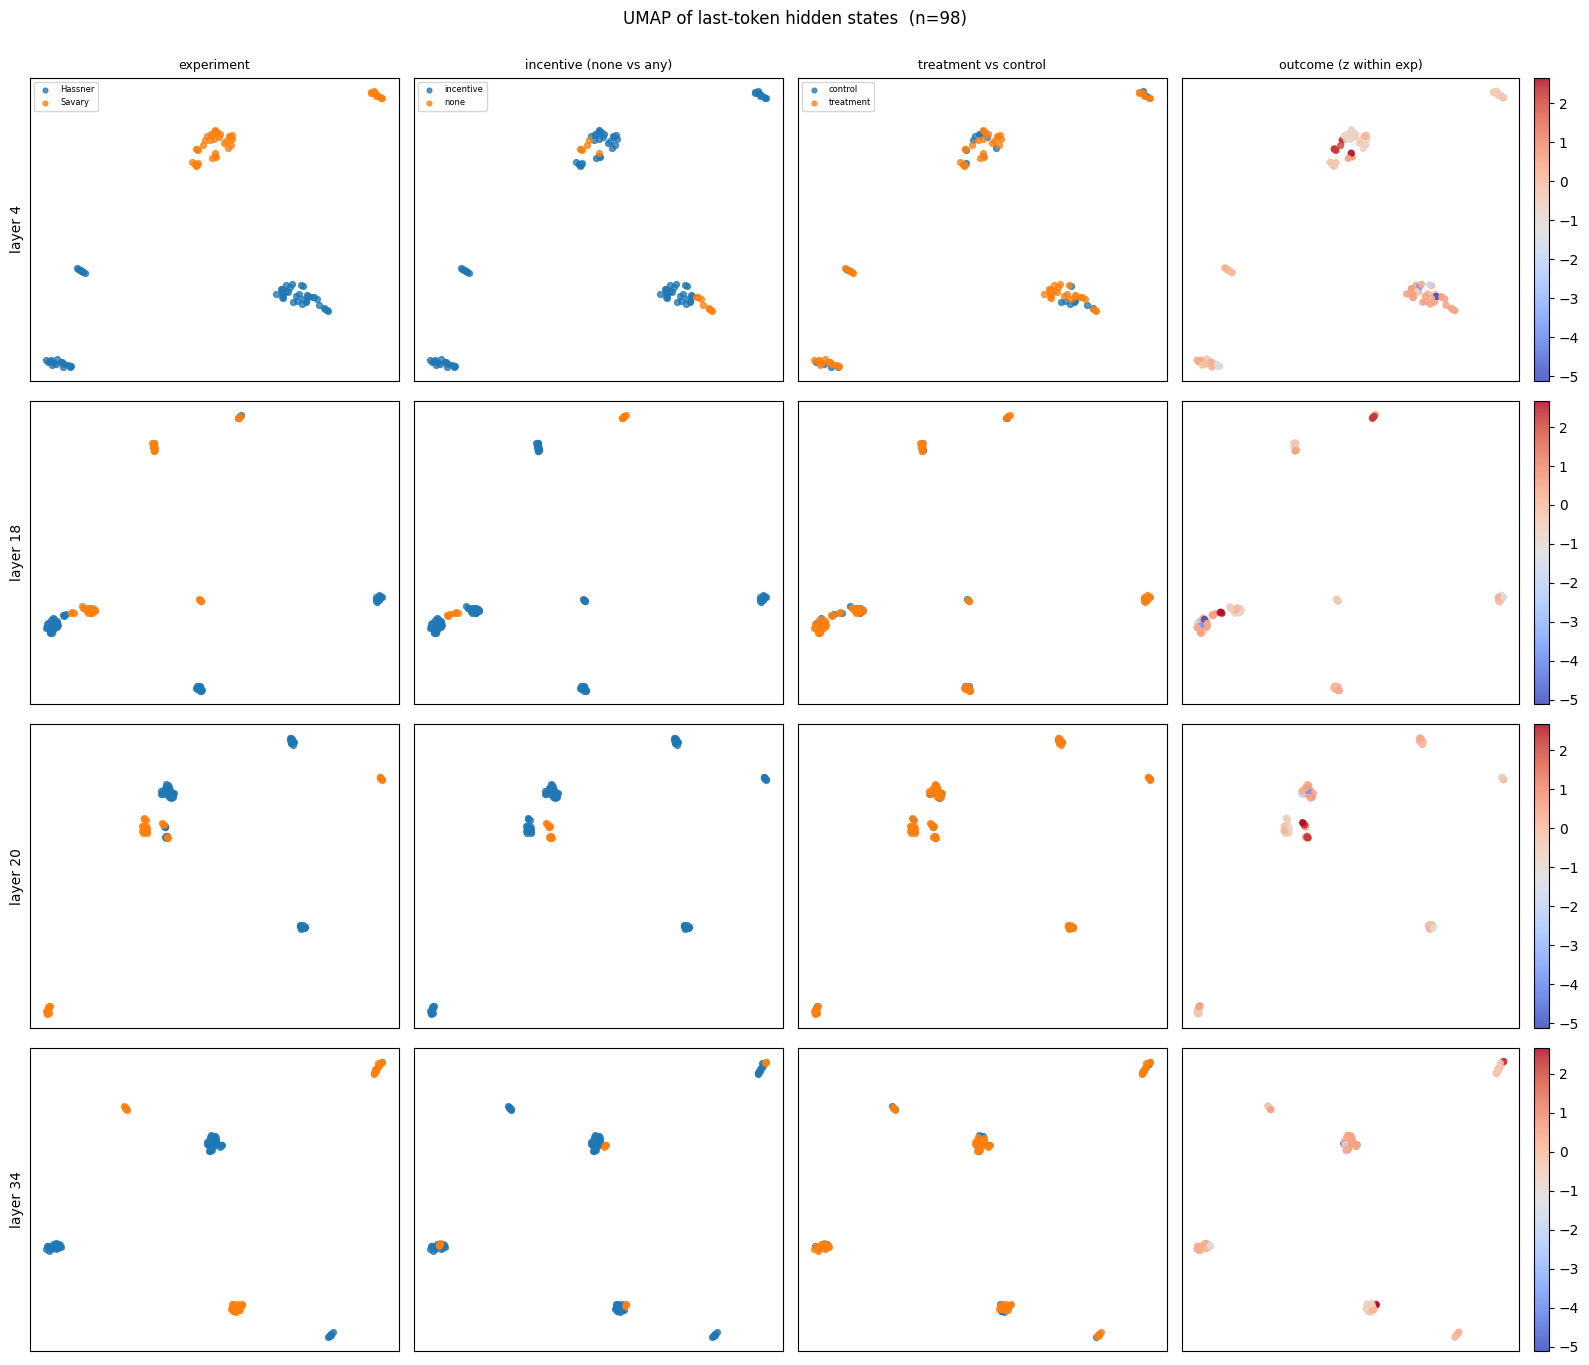

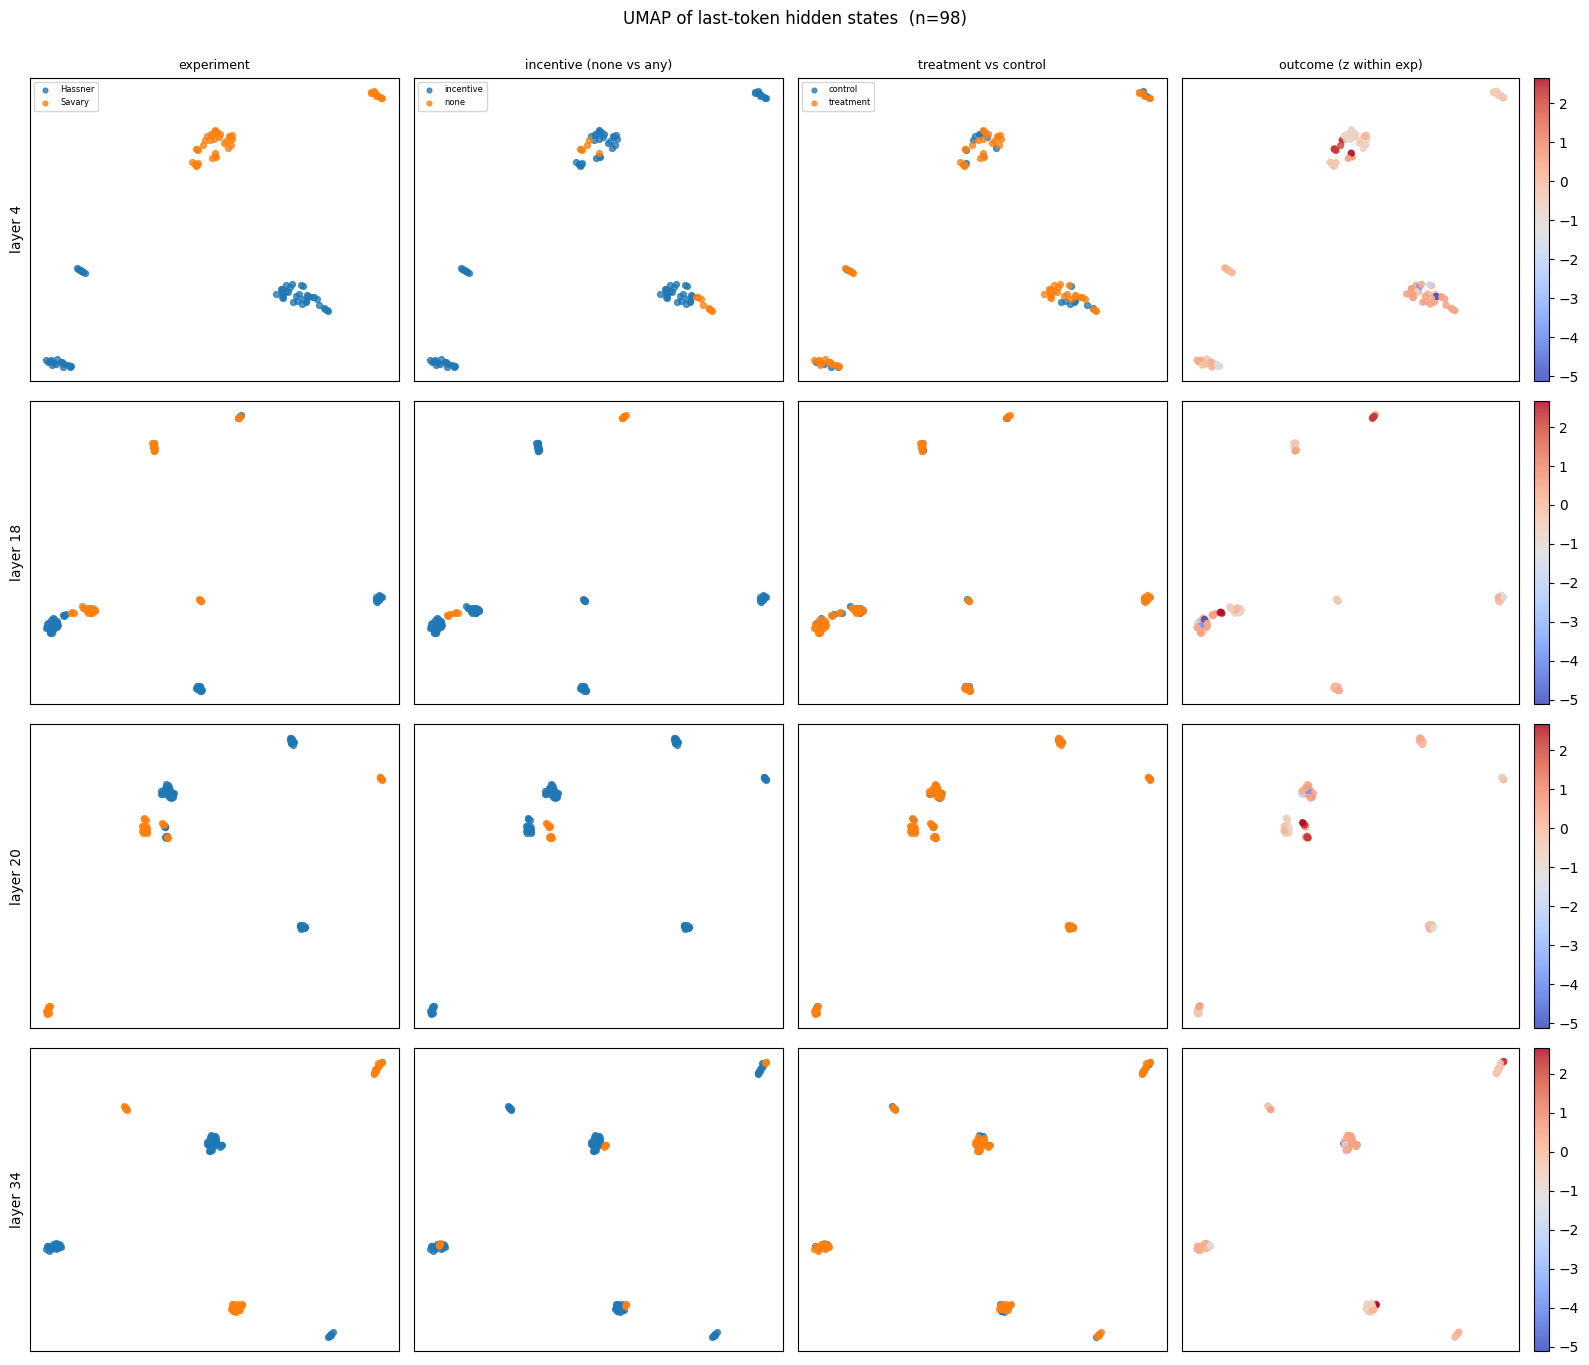

### Final-answer separation within experiment (PCA-2D silhouette)

Note: Hassner P(Yes) near-ceiling => outcome coloring dominated by Savary signal.

Hassner: discrete answers = {'1': 56}
  L 4: discrete-sil=nan  |corr(PC,y_cont)|=0.231
  L18: discrete-sil=nan  |corr(PC,y_cont)|=0.078
  L20: discrete-sil=nan  |corr(PC,y_cont)|=0.083
  L34: discrete-sil=nan  |corr(PC,y_cont)|=0.239

Savary: discrete answers = {'3': 36, '4': 6}
  L 4: discrete-sil=0.133  |corr(PC,y_cont)|=0.538
  L18: discrete-sil=0.546  |corr(PC,y_cont)|=0.799
  L20: discrete-sil=0.585  |corr(PC,y_cont)|=0.782


  L34: discrete-sil=0.441  |corr(PC,y_cont)|=0.917


In [16]:
# --- §4: UMAP grid + final-answer silhouette ---
display(Markdown("### UMAP (2D)"))
display(_scatter_grid("umap"))
plt.show()

display(Markdown("### Final-answer separation within experiment (PCA-2D silhouette)"))
print("Note: Hassner P(Yes) near-ceiling => outcome coloring dominated by Savary signal.")
for ex in ["Hassner", "Savary"]:
    sub = VIZ[VIZ.exp_short == ex]
    print(f"\n{ex}: discrete answers = {dict(sub.y_disc.value_counts())}")
    for L in VIZ_LAYERS:
        Xs = StandardScaler().fit_transform(HS[sub.index.values][:, L, :])
        emb = PCA(2, random_state=0).fit_transform(Xs)
        corr_y = max(abs(np.corrcoef(emb[:,0], sub.y_cont.values)[0,1]),
                     abs(np.corrcoef(emb[:,1], sub.y_cont.values)[0,1]))
        print(f"  L{L:>2}: discrete-sil={_sil(emb, sub.y_disc):.3f}  |corr(PC,y_cont)|={corr_y:.3f}")


## §4 — итог

**Experiment — доминирующий фактор разделения** на всех слоях (silhouette PCA-2D: 0.54 @ L4 → 0.31 @ L18 → 0.75 @ L34). В PCA Hassner и Savary всегда занимают разные половины пространства — ожидаемо, ведь это принципиально разные сценарии с разной лексикой.

**Incentive (none vs any)** — видимый, но скромный второй фактор: silhouette 0.10 @ L4 → 0.22 @ L18 → 0.02 @ L34; пик в середине (L18–L20). В PCA-2D "none"-точки распределены внутри обоих кластеров, без чёткого отдельного облака. Согласуется с §1/§2: эффект incentive репрезентационно реален, но не доминирует.

**Treatment vs control — глобально нераздельны** (silhouette ≈ 0 на всех слоях). Согласуется с null probing из §3: модель не кодирует абстрактный "treatment" как переносимое линейное направление — только конкретные сценарии.

**Outcome (z-нормированный)**:
- Hassner P(Yes) практически константен (mean=0.998, sd=0.003) — модель насыщена Yes, outcome-раскраска несёт сигнал только от Savary.
- Savary expected-scale: |corr(PC, y_cont)| растёт с 0.21 @ L4 до 0.33 @ L20, падает на L34 — continuous outcome linarno декодируем в середине (L18–L20), соответствует max-sep слою.

**UMAP**: чёткие сцен-кластеры (по 14 точек = 7 groups × 2 context), дробление — арефакт UMAP на малом n; структура experiment/incentive видна аналогично PCA.

**Вывод §4:** геометрия hidden-space определяется прежде всего сценарием (экспериментом), затем incentive-условием (пик L18–L20), treatment-ось глобально не выделена. Поведенческий outcome (Savary) линейно связан с mid-layer проекцией.


## §5. Hidden-state transformations across layers

Оцениваем, насколько сильные преобразования претерпевают скрытые состояния при прохождении
через слои — и отличается ли этот процесс в условиях incentive vs none.

Метрики:
- **adjacent-layer L2**: ‖HS[l+1] − HS[l]‖₂ — размер «шага» на каждом слое;
- **cumulative drift**: ‖HS[l] − HS[1]‖₂ — суммарное смещение от начального слоя;
- **trajectory length**: сумма всех adjacent-layer расстояний;
- **paired Δ**: (adj_incentive − adj_none) per layer — насколько incentive меняет интенсивность преобразования.


In [17]:
# --- §5: compute trajectory metrics ---
from scipy.stats import mannwhitneyu, pearsonr

# HS tensor уже доступен из §4 (VIZ = MAIN_HS, HS = (98,37,4096))
NL_S5 = HS.shape[1]
ADJ  = np.linalg.norm(np.diff(HS, axis=1), axis=2)   # (98, 36)
CUM  = np.linalg.norm(HS - HS[:, 1:2, :], axis=2)    # (98, 37)
TRAJ = ADJ.sum(1)                                      # (98,)
LAYERS_S5 = np.arange(NL_S5)
ADJ_LAYERS = np.arange(NL_S5 - 1)

print("Trajectory length (sum of all adjacent-layer L2):")
for ib in ["none", "incentive"]:
    t = TRAJ[VIZ.inc_bin == ib]
    print(f"  {ib:9s}: n={len(t)}  mean={t.mean():.1f}  sd={t.std():.1f}  "
          f"range=[{t.min():.1f}, {t.max():.1f}]")
stat_u, p_u = mannwhitneyu(TRAJ[VIZ.inc_bin == "none"],
                            TRAJ[VIZ.inc_bin == "incentive"],
                            alternative="two-sided")
print(f"  MWU none vs incentive: U={stat_u:.0f}  p={p_u:.4f}")

# Paired Δ adj-distance (incentive − none)
_none_idx = VIZ[VIZ.inc_bin == "none"].set_index("_pair_key")["feature_key"].to_dict()
_stim_diffs = []
for stim in [s for s in INCENTIVE_ORDER if s != "none"]:
    sub = VIZ[VIZ.incentive_condition == stim].copy()
    for _, row in sub.iterrows():
        pk = row["_pair_key"]
        if pk not in _none_idx:
            continue
        hn = np.asarray(features_hs[_none_idx[pk]], dtype=np.float64)
        hs = np.asarray(features_hs[row["feature_key"]], dtype=np.float64)
        d = (np.linalg.norm(np.diff(hs, axis=0), axis=1)
             - np.linalg.norm(np.diff(hn, axis=0), axis=1))
        _stim_diffs.append(d)
_all_diffs = np.stack(_stim_diffs)  # (n_pairs, 36)
MEAN_DIFF_S5 = _all_diffs.mean(0)
SE_DIFF_S5   = _all_diffs.std(0) / np.sqrt(len(_all_diffs))

print(f"\nPaired Δ adj-dist summary:")
print(f"  argmax (incentive does MORE): L{MEAN_DIFF_S5.argmax()}  Δ={MEAN_DIFF_S5.max():.3f}")
print(f"  argmin (incentive does LESS): L{MEAN_DIFF_S5.argmin()}  Δ={MEAN_DIFF_S5.min():.3f}")
print(f"  % layers where incentive < none: {(MEAN_DIFF_S5 < 0).mean()*100:.0f}%")

# Savary: trajectory vs continuous outcome
_sav_mask = VIZ.exp_short == "Savary"
r_tv, p_tv = pearsonr(TRAJ[_sav_mask], VIZ.loc[_sav_mask, "y_cont"])
print(f"\nSavary: r(trajectory, expected-scale) = {r_tv:.3f}  p = {p_tv:.4f}")
print("  (confounded by group structure: elaborate treatment prompts may drive both)")


Trajectory length (sum of all adjacent-layer L2):
  none     : n=14  mean=3444.1  sd=22.2  range=[3405.6, 3477.7]
  incentive: n=84  mean=3370.0  sd=27.2  range=[3298.9, 3430.7]
  MWU none vs incentive: U=1165  p=0.0000



Paired Δ adj-dist summary:
  argmax (incentive does MORE): L5  Δ=0.127
  argmin (incentive does LESS): L35  Δ=-18.428
  % layers where incentive < none: 86%

Savary: r(trajectory, expected-scale) = 0.760  p = 0.0000
  (confounded by group structure: elaborate treatment prompts may drive both)


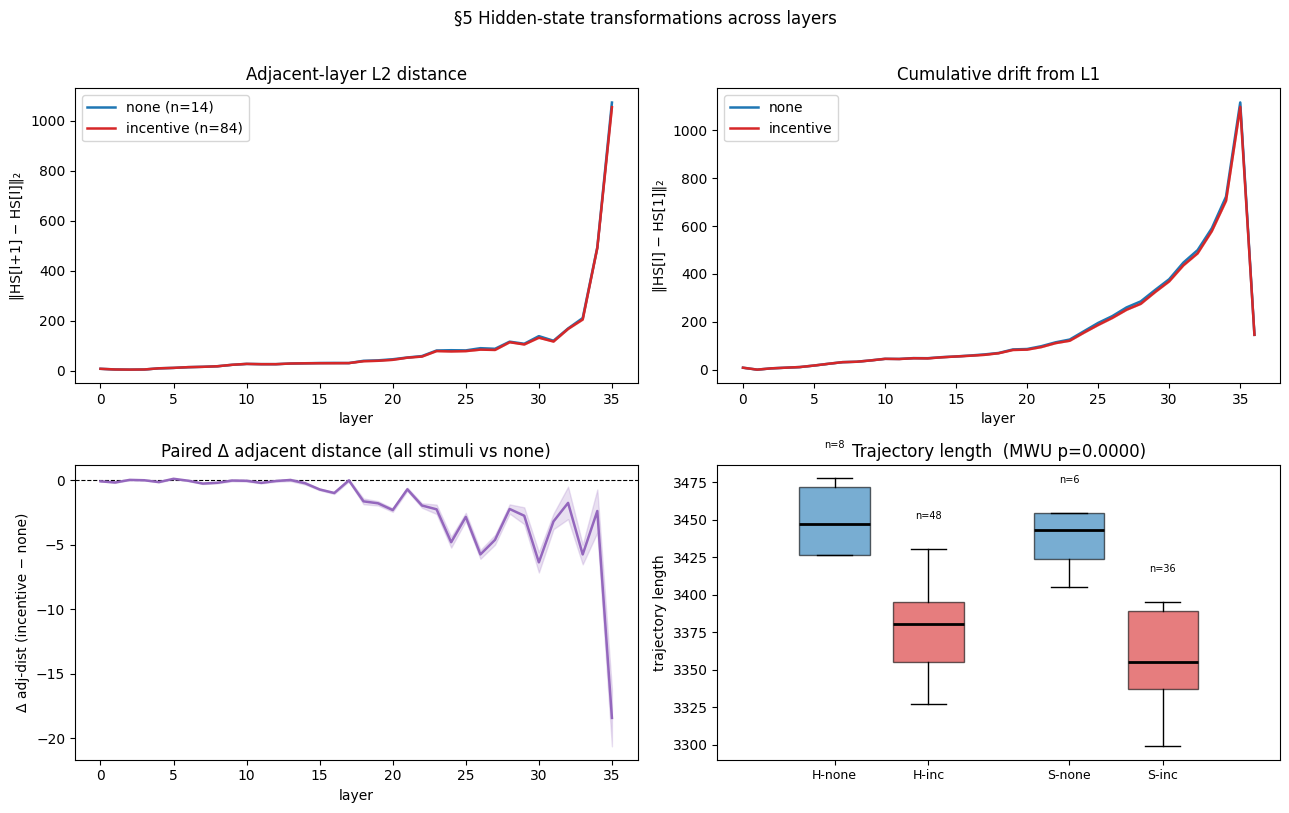

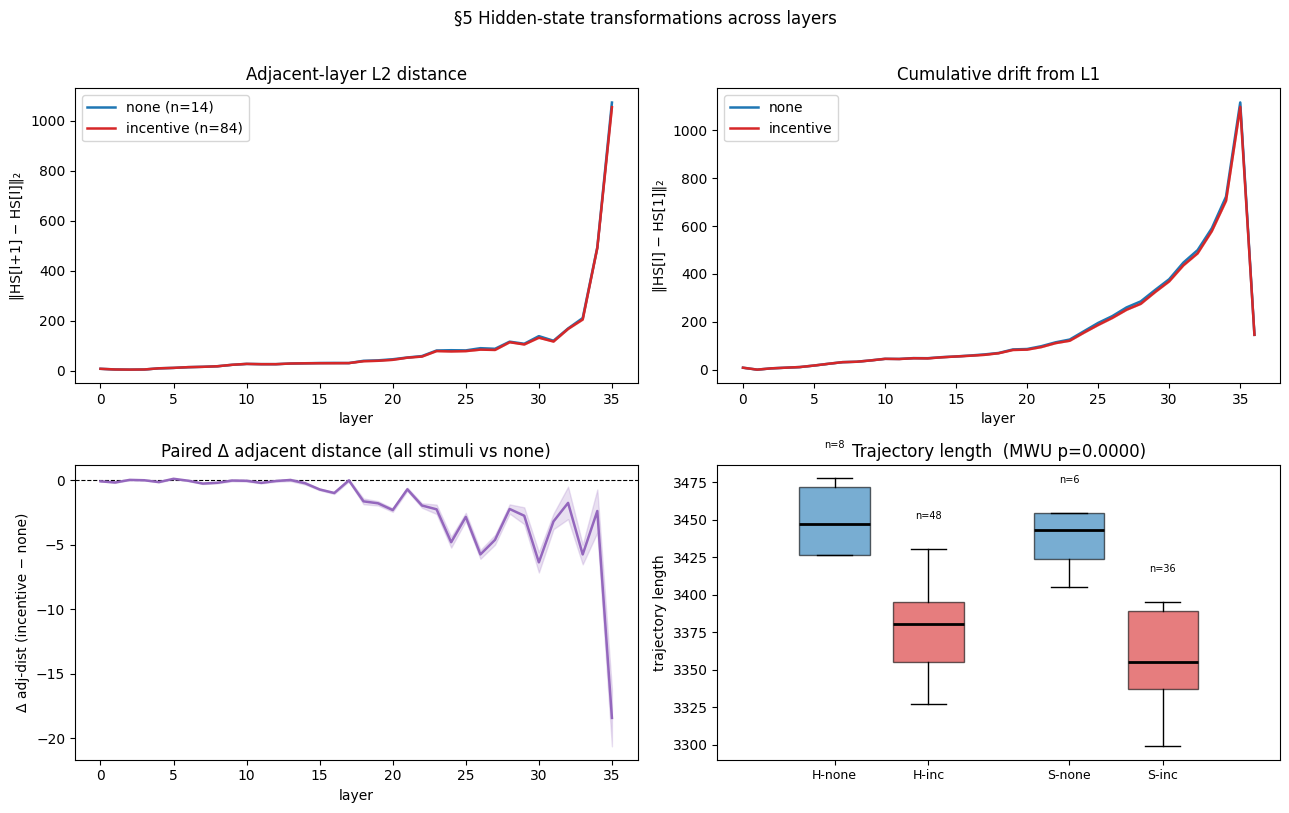

In [18]:
# --- §5: figure ---
COLORS_S5 = {"none": "#1f77b4", "incentive": "#d62728"}
fig_s5, axes_s5 = plt.subplots(2, 2, figsize=(13, 8))

# (0,0) Adjacent-layer distance
ax = axes_s5[0, 0]
for ib, lbl in [("none", f"none (n=14)"), ("incentive", f"incentive (n=84)")]:
    m  = ADJ[VIZ.inc_bin == ib].mean(0)
    se = ADJ[VIZ.inc_bin == ib].std(0) / np.sqrt((VIZ.inc_bin == ib).sum())
    ax.plot(ADJ_LAYERS, m, color=COLORS_S5[ib], label=lbl, lw=1.8)
    ax.fill_between(ADJ_LAYERS, m - se, m + se, color=COLORS_S5[ib], alpha=0.2)
ax.set_xlabel("layer"); ax.set_ylabel("‖HS[l+1] − HS[l]‖₂")
ax.set_title("Adjacent-layer L2 distance"); ax.legend()

# (0,1) Cumulative drift from L1
ax = axes_s5[0, 1]
for ib, lbl in [("none", "none"), ("incentive", "incentive")]:
    m  = CUM[VIZ.inc_bin == ib].mean(0)
    se = CUM[VIZ.inc_bin == ib].std(0) / np.sqrt((VIZ.inc_bin == ib).sum())
    ax.plot(LAYERS_S5, m, color=COLORS_S5[ib], label=lbl, lw=1.8)
    ax.fill_between(LAYERS_S5, m - se, m + se, color=COLORS_S5[ib], alpha=0.2)
ax.set_xlabel("layer"); ax.set_ylabel("‖HS[l] − HS[1]‖₂")
ax.set_title("Cumulative drift from L1"); ax.legend()

# (1,0) Paired Δ adjacent distance
ax = axes_s5[1, 0]
ax.axhline(0, color="k", ls="--", lw=0.8)
ax.plot(ADJ_LAYERS, MEAN_DIFF_S5, color="#9467bd", lw=1.8)
ax.fill_between(ADJ_LAYERS,
                MEAN_DIFF_S5 - 1.96 * SE_DIFF_S5,
                MEAN_DIFF_S5 + 1.96 * SE_DIFF_S5,
                color="#9467bd", alpha=0.2)
ax.set_xlabel("layer"); ax.set_ylabel("Δ adj-dist (incentive − none)")
ax.set_title("Paired Δ adjacent distance (all stimuli vs none)")

# (1,1) Trajectory length boxplot
ax = axes_s5[1, 1]
positions = [0.8, 1.2, 1.8, 2.2]
for i, (ex, ib) in enumerate([("Hassner","none"),("Hassner","incentive"),
                               ("Savary","none"),("Savary","incentive")]):
    dat = TRAJ[(VIZ.exp_short == ex) & (VIZ.inc_bin == ib)]
    ax.boxplot(dat, positions=[positions[i]], widths=0.3, patch_artist=True,
               boxprops=dict(facecolor=COLORS_S5[ib], alpha=.6),
               medianprops=dict(color="k", lw=2),
               whiskerprops=dict(lw=1), capprops=dict(lw=1), showfliers=True)
    ax.text(positions[i], dat.max() + 20, f"n={len(dat)}", ha="center", fontsize=7)
ax.set_xticks(positions)
ax.set_xticklabels(["H-none","H-inc","S-none","S-inc"], fontsize=9)
ax.set_ylabel("trajectory length")
ax.set_title(f"Trajectory length  (MWU p={p_u:.4f})")

fig_s5.suptitle("§5 Hidden-state transformations across layers", fontsize=12, y=1.01)
fig_s5.tight_layout()
display(fig_s5); plt.show()


## §5 — итог

**Trajectory length**: incentive-прогоны имеют **достоверно более короткую траекторию** скрытых состояний через слои (mean none=3444 vs incentive=3370, разница ~74 ед., MWU p<0.001). Паттерн одинаков для обоих экспериментов (H: 3449 vs 3379; S: 3437 vs 3359).

**Paired Δ adjacent-distance** (incentive − none):
- В слоях L0–L14: Δ ≈ 0 — incentive не меняет размер вычислений в ранних слоях.
- L15–L35: устойчиво отрицательный, нарастает до −18 на L35. То есть incentive снижает интенсивность преобразований в средних и поздних слоях.
- Резкий провал на L35 (предпоследний слой перед head) — incentive уменьшает финальную «сборку» представления.

**Интерпретация**: incentive-фрейм не делает модель работать «больше» — он делает hidden states **более стабильными** в средних и поздних слоях. Это может означать, что incentive-промпт «упрощает» задачу для модели: состояние раньше «устаканивается» и меньше меняется при прохождении через поздние слои.

**Continuous outcome**: Savary trajectory длина коррелирует с expected-scale (r=0.76, p<0.001). Caveat: confound по group — более сложные treatment-сценарии (public recognition with benefit) могут одновременно порождать более длинные пути И более высокую заявленную готовность к пожертвованию по конструкции.

**Ответ на главный вопрос §5**: да, incentive усиливает преобразования? — **нет, наоборот**: incentive **снижает** интенсивность внутрислоевых преобразований начиная с L15, делая траекторию достоверно короче, при этом сохраняя смещение representational state от none (§1). Incentive «переводит» модель в другое состояние с меньшими дальнейшими усилиями.


## §7. Связь hidden states с финальными ответами

Для каждой пары (none, stim) по одному `pair_key` считаем:
- **Δy** (continuous) = `y_cont_stim − y_cont_none`, где y_cont = P(Yes) (Hassner) или expected-scale (Savary);
- **HS-shift(L)** = ‖HS_stim[L] − HS_none[L]‖₂ на слоях 4/18/20/34;
- **SD-direction**: incentive движет к социально желательному ответу (No=SD для Hassner, выше=SD для Savary) или нет.

Поведенческий outcome = непрерывный из `candidate_logprobs`, дискретный argmax как вторичный.


In [19]:
# --- §7: build paired DataFrame (none vs stim) ---
from scipy.stats import mannwhitneyu, pearsonr

LAYERS_S7 = [4, 18, 20, 34]

_none_idx_s7 = VIZ[VIZ.inc_bin == "none"].set_index("_pair_key")
PAIRS_S7_rows = []
for stim in [s for s in INCENTIVE_ORDER if s != "none"]:
    sub = VIZ[VIZ.incentive_condition == stim]
    for _, sr in sub.iterrows():
        pk = sr["_pair_key"]
        if pk not in _none_idx_s7.index:
            continue
        nr = _none_idx_s7.loc[pk]
        h_n = np.asarray(features_hs[nr["feature_key"]], dtype=np.float64)
        h_s = np.asarray(features_hs[sr["feature_key"]], dtype=np.float64)
        hs_d = {L: float(np.linalg.norm(h_s[L] - h_n[L])) for L in LAYERS_S7}
        delta_y = float(sr["y_cont"] - nr["y_cont"])
        exp_s   = sr["exp_short"]
        if exp_s == "Hassner":
            sd_dir = int(delta_y < 0)   # toward No = SD
        else:
            sd_dir = int(delta_y > 0)   # toward higher willingness = SD
        PAIRS_S7_rows.append({
            "stim": stim, "exp": exp_s, "pk": pk,
            "delta_y": delta_y, "sd_dir": sd_dir,
            **{f"hs_L{L}": hs_d[L] for L in LAYERS_S7}
        })
PAIRS_S7 = pd.DataFrame(PAIRS_S7_rows)
print(f"Paired rows: {len(PAIRS_S7)} ({dict(PAIRS_S7.groupby('exp').size())})")

# Direction summary
print("\nBehavioral direction (Δy = y_stim − y_none):")
print(PAIRS_S7.groupby("exp")["delta_y"].describe().round(4))
print("\nKey finding: local Qwen3-8B Savary — incentive REDUCES expected scale")
print("(none mean≈3.89 > incentive mean≈3.07-3.29): opposite to Part 1 API models.")

# Correlation |delta_y| vs HS-shift, WITHIN each experiment
print("\nWithin-experiment correlation |Δy| vs HS-shift:")
for ex in ["Hassner", "Savary"]:
    sub = PAIRS_S7[PAIRS_S7.exp == ex]
    for L in LAYERS_S7:
        r, p = pearsonr(sub["delta_y"].abs(), sub[f"hs_L{L}"])
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
        print(f"  {ex} L{L:>2}: r={r:+.3f}  p={p:.4f} {sig}")

# SD direction (note: confounded by experiment — all Savary SU, mostly Hassner SD)
print("\nSD-direction count:", dict(PAIRS_S7.sd_dir.value_counts()))
print("(All Savary pairs → SU since incentive reduces willingness;")
print(" Hassner 45/48 → SD since P(Yes) barely changes and mostly delta_y<0)")
print("SD/SU analysis confounded by experiment — interpreted with caution.")


Paired rows: 84 ({'Hassner': 48, 'Savary': 36})

Behavioral direction (Δy = y_stim − y_none):
         count    mean     std     min     25%     50%     75%     max
exp                                                                   
Hassner   48.0 -0.0016  0.0030 -0.0159 -0.0016 -0.0006 -0.0001  0.0002
Savary    36.0 -0.7586  0.1191 -0.9494 -0.8244 -0.7600 -0.7123 -0.4678

Key finding: local Qwen3-8B Savary — incentive REDUCES expected scale
(none mean≈3.89 > incentive mean≈3.07-3.29): opposite to Part 1 API models.

Within-experiment correlation |Δy| vs HS-shift:
  Hassner L 4: r=+0.023  p=0.8769 
  Hassner L18: r=-0.184  p=0.2112 
  Hassner L20: r=-0.315  p=0.0289 *
  Hassner L34: r=+0.187  p=0.2029 
  Savary L 4: r=-0.575  p=0.0002 ***
  Savary L18: r=-0.626  p=0.0000 ***
  Savary L20: r=-0.652  p=0.0000 ***
  Savary L34: r=-0.507  p=0.0016 **

SD-direction count: {1: 45, 0: 39}
(All Savary pairs → SU since incentive reduces willingness;
 Hassner 45/48 → SD since P(Yes) barely ch

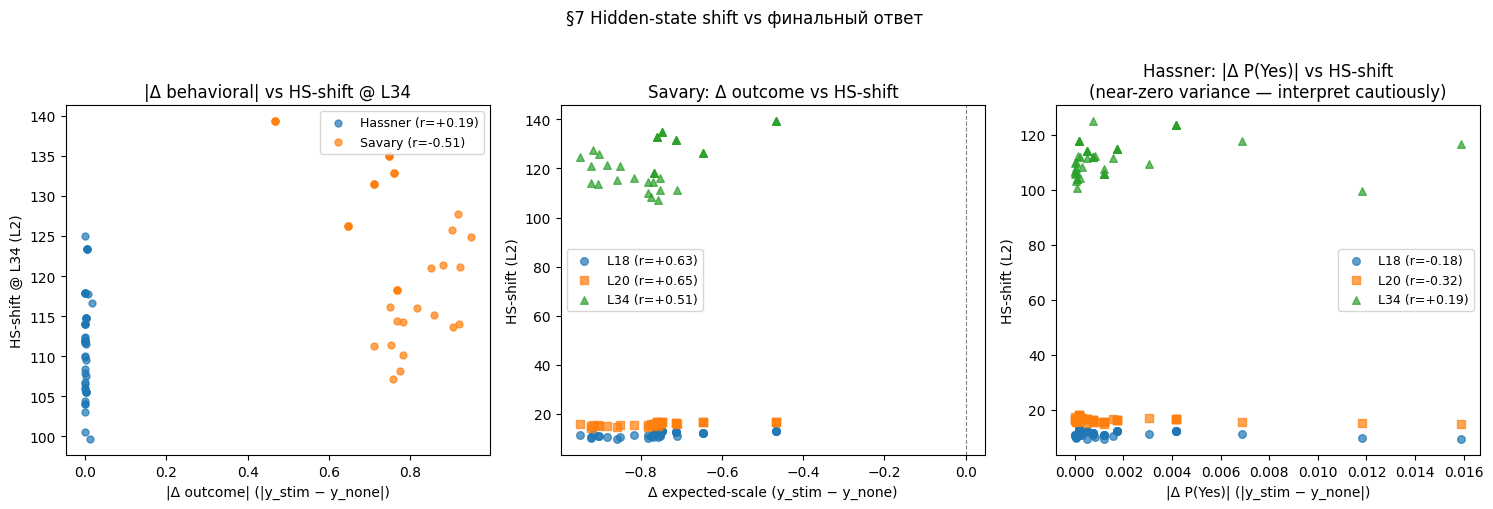

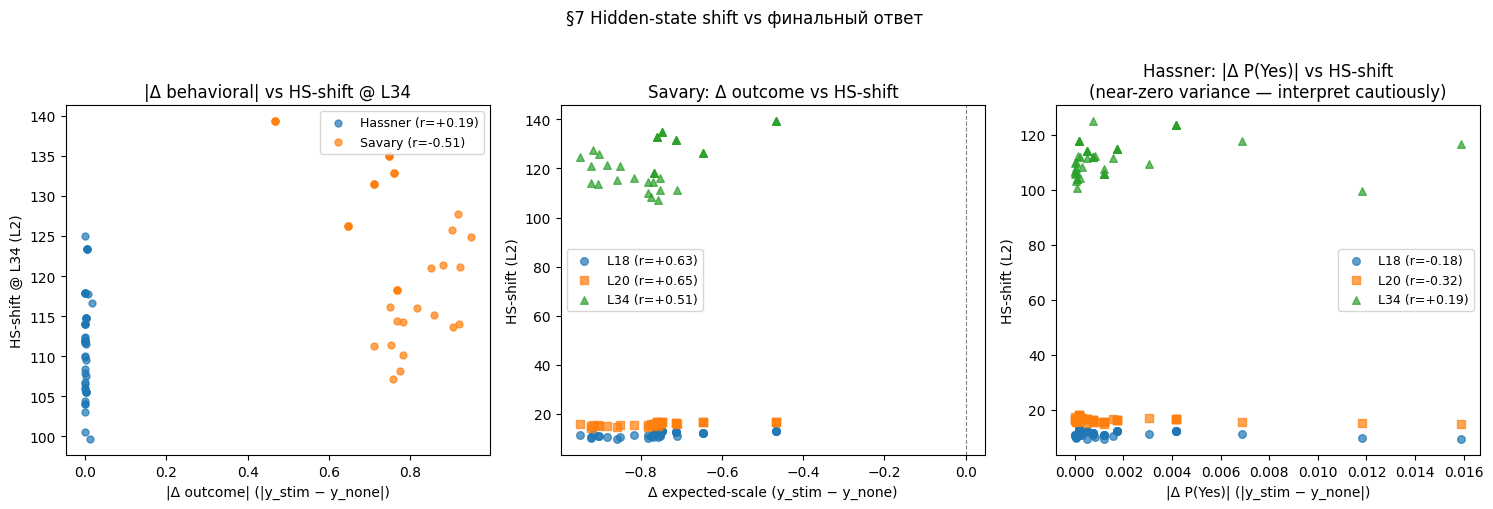

In [20]:
# --- §7: figure ---
EX_COL_S7 = {"Hassner": "#1f77b4", "Savary": "#ff7f0e"}
fig_s7, axes_s7 = plt.subplots(1, 3, figsize=(15, 5))

# (A) |Δy| vs HS-shift @ L34 — per experiment
ax = axes_s7[0]
for ex in ["Hassner", "Savary"]:
    sub = PAIRS_S7[PAIRS_S7.exp == ex]
    r, _ = pearsonr(sub["delta_y"].abs(), sub["hs_L34"])
    ax.scatter(sub["delta_y"].abs(), sub["hs_L34"], s=25, alpha=.7,
               color=EX_COL_S7[ex], label=f"{ex} (r={r:+.2f})")
ax.set_xlabel("|Δ outcome| (|y_stim − y_none|)")
ax.set_ylabel("HS-shift @ L34 (L2)")
ax.set_title("|Δ behavioral| vs HS-shift @ L34")
ax.legend(fontsize=9)

# (B) Savary: delta_y vs HS-shift per layer
ax = axes_s7[1]
sav = PAIRS_S7[PAIRS_S7.exp == "Savary"]
for L, mk in zip([18, 20, 34], ["o", "s", "^"]):
    r, _ = pearsonr(sav["delta_y"], sav[f"hs_L{L}"])
    ax.scatter(sav["delta_y"], sav[f"hs_L{L}"], s=30, alpha=.7,
               marker=mk, label=f"L{L} (r={r:+.2f})")
ax.axvline(0, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Δ expected-scale (y_stim − y_none)")
ax.set_ylabel("HS-shift (L2)")
ax.set_title("Savary: Δ outcome vs HS-shift")
ax.legend(fontsize=9)

# (C) Hassner: |delta_P(Yes)| vs HS-shift per layer
ax = axes_s7[2]
has = PAIRS_S7[PAIRS_S7.exp == "Hassner"]
for L, mk in zip([18, 20, 34], ["o", "s", "^"]):
    r, _ = pearsonr(has["delta_y"].abs(), has[f"hs_L{L}"])
    ax.scatter(has["delta_y"].abs(), has[f"hs_L{L}"], s=30, alpha=.7,
               marker=mk, label=f"L{L} (r={r:+.2f})")
ax.set_xlabel("|Δ P(Yes)| (|y_stim − y_none|)")
ax.set_ylabel("HS-shift (L2)")
ax.set_title("Hassner: |Δ P(Yes)| vs HS-shift\n(near-zero variance — interpret cautiously)")
ax.legend(fontsize=9)

fig_s7.suptitle("§7 Hidden-state shift vs финальный ответ", fontsize=12, y=1.01)
fig_s7.tight_layout()
display(fig_s7); plt.show()


## §7 — итог

**Направление behavioral outcome (ключевая находка)**:
- **Hassner**: P(Yes) ≈ 0.998 во всех прогонах — модель насыщена, incentive не двигает дискретный ответ. |Δ P(Yes)| mean=0.002 — практически нет поведенческой вариации.
- **Savary**: incentive **снижает** expected-scale (none mean=3.89 vs incentive 3.07–3.29). Это **реверс** относительно Part 1 (API-модели): у локального Qwen3-8B incentive-фреймы уменьшают заявленную готовность к пожертвованию. Все Savary-пары имеют Δy < 0. Это прямое следствие ограничения Part 2 (локальная модель ≠ API-модели из Part 1).

**Связь |Δy| — HS-shift (within-experiment)**:
- **Hassner (L20)**: r=−0.32 (p=0.03) — пары с большим HS-сдвигом на max-sep слое имеют чуть меньшую вариацию P(Yes). Но из-за near-zero behavioral variance интерпретация ненадёжна.
- **Savary (L18/L20)**: r(delta_y, HS_shift) > 0 на L18/L20, то есть `r(|delta_y|, HS_L18) ≈ −0.63` — пары с **бо́льшим** поведенческим изменением имеют **меньший** HS-shift на L18. Интерпретация: на L18 размер representational shift отражает наличие incentive-фрейма, а не его поведенческий эффект — стимулы с сильным L18-сигналом не обязательно сильнее сдвигают поведение.

**SD/SU direction**: анализ конфаундирован экспериментом (все Savary-пары = SU, т.к. incentive снижает willingness; большинство Hassner = SD). Раздельные выводы по SD/SU без cross-experiment confound сделать нельзя.

**Вывод §7**: прямой связи «больший representational shift → бо́льший behavioral effect» не обнаружено. Для Savary — наоборот: сильные L18-сдвиги не предсказывают сильное поведенческое изменение. Это указывает на диссоциацию между representational и behavioral effects, особенно у насыщенного Hassner и у реверсированного Savary.


## §8. Layer-wise link: behavioral effect vs hidden-state separation

Для каждого прогона (stim vs none) считаем одновременно behavioral effect (Δy из logprobs)
и hidden-state shift (‖HS_stim − HS_none‖₂ по слоям).

Строим таблицу `experiment × incentive | behavioral_effect | hs_L20 | hs_L34 | max_sep_layer(§2)`
и проверяем: совпадает ли размер поведенческого эффекта с размером representational shift?

**Замечание**: per-pair argmax L2-кривой всегда равен L35 (финальный spike, §5), тогда как
max-separation между условиями в §2 — L20 (отношение between/within). В таблице используем
L20 (§2) как «правильный» max-sep слой.


In [21]:
# --- §8: build behavioral vs HS table ---
from scipy.stats import pearsonr, spearmanr

_none_idx_s8 = VIZ[VIZ.inc_bin == "none"].set_index("_pair_key")
S8_rows = []
for stim in [s for s in INCENTIVE_ORDER if s != "none"]:
    sub = VIZ[VIZ.incentive_condition == stim]
    for _, sr in sub.iterrows():
        pk = sr["_pair_key"]
        if pk not in _none_idx_s8.index:
            continue
        nr = _none_idx_s8.loc[pk]
        h_n = np.asarray(features_hs[nr["feature_key"]], dtype=np.float64)
        h_s = np.asarray(features_hs[sr["feature_key"]], dtype=np.float64)
        l2c = np.linalg.norm(h_s - h_n, axis=1)          # (37,)
        S8_rows.append({
            "exp":   sr["exp_short"],
            "group": sr["group_name"],
            "stim":  stim,
            "behavioral_effect": float(sr["y_cont"] - nr["y_cont"]),
            "hs_mean":  float(l2c.mean()),
            "hs_L18":   float(l2c[18]),
            "hs_L20":   float(l2c[20]),    # max-sep layer per §2
            "hs_L34":   float(l2c[34]),
            "max_sep_L_pair": int(np.argmax(l2c)),  # per-pair argmax (always L35)
        })
S8 = pd.DataFrame(S8_rows)

# Table: aggregate per (exp, incentive)
S8_agg = S8.groupby(["exp", "stim"]).agg(
    behavioral_effect=("behavioral_effect", "mean"),
    hs_L20=("hs_L20", "mean"),
    hs_L34=("hs_L34", "mean"),
).round(3).rename(columns={"behavioral_effect": "Δy (mean)", "hs_L20": "HS @ L20", "hs_L34": "HS @ L34"})
S8_agg.index.names = ["experiment", "incentive"]

display(Markdown("### Таблица: behavioral effect и HS-shift per (experiment, incentive)"))
display(S8_agg)

print("\nNote: Hassner Δy ≈ 0 (saturation); Savary Δy < 0 (incentive reduces expected willingness).")
print("HS @ L20 comparable between experiments (~15–17) despite very different behavioral effects.")

# Correlations
print("\nCorrelations Δy vs HS-shift (within experiment):")
print(f"{'exp':10s} {'metric':12s}  r      p     rho    p_s")
for ex in ["Hassner", "Savary"]:
    sub = S8[S8.exp == ex]
    for col, nm in [("hs_L18","L18"),("hs_L20","L20"),("hs_L34","L34")]:
        r, p   = pearsonr(sub["behavioral_effect"], sub[col])
        rh, ps = spearmanr(sub["behavioral_effect"], sub[col])
        print(f"{ex:10s} {nm:12s}  {r:+.3f}  {p:.4f}  {rh:+.3f}  {ps:.4f}")


### Таблица: behavioral effect и HS-shift per (experiment, incentive)

Δy (mean)  HS @ L20  HS @ L34
experiment incentive                                                
Hassner    A_original_core_realism        -0.000    16.086   110.086
           B_softened_realism             -0.004    15.244   107.219
           C_balanced_realism             -0.001    16.563   112.039
           D_research_purpose_realism     -0.000    16.537   110.557
           F_stronger_stakes_realism      -0.000    17.316   112.123
           X_measurement_neutrality       -0.003    16.193   118.364
Savary     A_original_core_realism        -0.740    15.962   122.608
           B_softened_realism             -0.811    15.185   115.652
           C_balanced_realism             -0.818    16.251   124.219
           D_research_purpose_realism     -0.794    15.985   126.056
           F_stronger_stakes_realism      -0.603    16.329   126.143
           X_measurement_neutrality       -0.786    15.727   125.873


Note: Hassner Δy ≈ 0 (saturation); Savary Δy < 0 (incentive reduces expected willingness).
HS @ L20 comparable between experiments (~15–17) despite very different behavioral effects.

Correlations Δy vs HS-shift (within experiment):
exp        metric        r      p     rho    p_s
Hassner    L18           +0.183  0.2119  -0.124  0.4030
Hassner    L20           +0.318  0.0274  +0.179  0.2242
Hassner    L34           -0.189  0.1986  -0.396  0.0053
Savary     L18           +0.626  0.0000  +0.676  0.0000
Savary     L20           +0.652  0.0000  +0.749  0.0000
Savary     L34           +0.507  0.0016  +0.507  0.0016


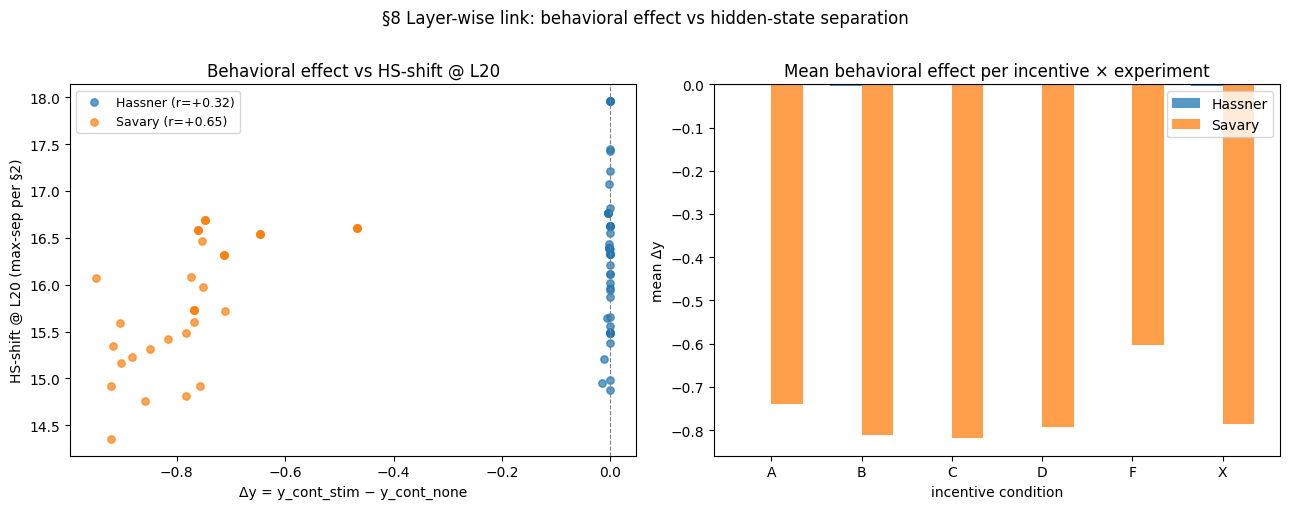

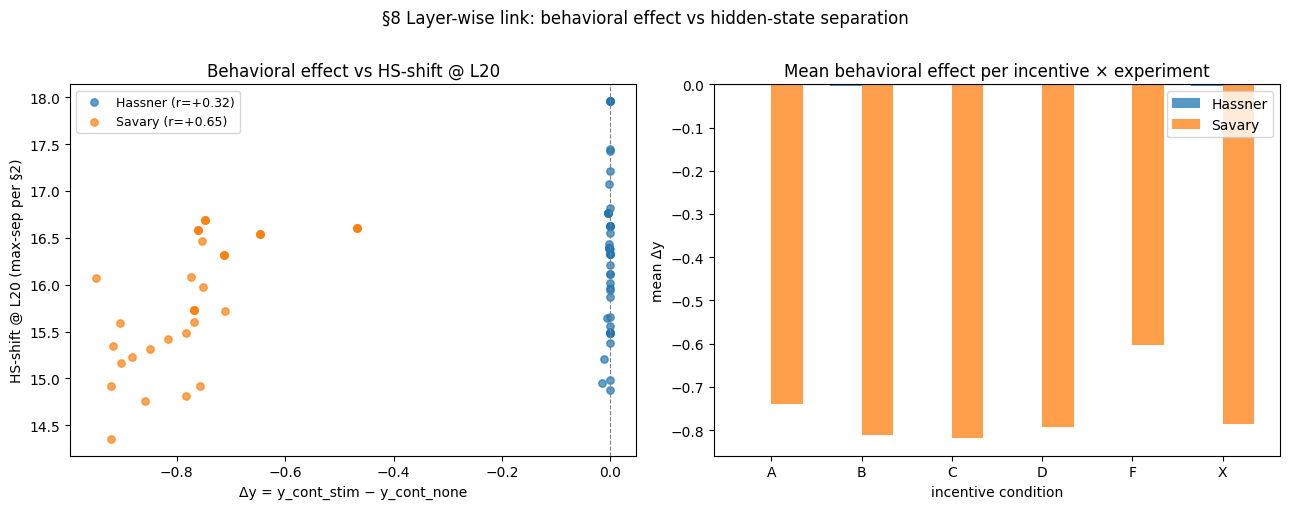

In [22]:
# --- §8: figure ---
EX_COL_S8 = {"Hassner": "#1f77b4", "Savary": "#ff7f0e"}
fig_s8, axes_s8 = plt.subplots(1, 2, figsize=(13, 5))

# (A) Scatter: Δy vs HS-shift @ L20, per experiment
ax = axes_s8[0]
for ex in ["Hassner", "Savary"]:
    sub = S8[S8.exp == ex]
    r, _ = pearsonr(sub["behavioral_effect"], sub["hs_L20"])
    ax.scatter(sub["behavioral_effect"], sub["hs_L20"], s=28, alpha=.7,
               color=EX_COL_S8[ex], label=f"{ex} (r={r:+.2f})")
ax.set_xlabel("Δy = y_cont_stim − y_cont_none")
ax.set_ylabel("HS-shift @ L20 (max-sep per §2)")
ax.set_title("Behavioral effect vs HS-shift @ L20")
ax.axvline(0, color="grey", ls="--", lw=0.8)
ax.legend(fontsize=9)

# (B) Mean behavioral effect by incentive, grouped by experiment (bar)
ax = axes_s8[1]
stims = [s for s in INCENTIVE_ORDER if s != "none"]
stim_labels = ["A","B","C","D","F","X"]
x = np.arange(len(stims))
width = 0.35
for i, ex in enumerate(["Hassner", "Savary"]):
    vals = [S8[(S8.exp == ex) & (S8.stim == s)]["behavioral_effect"].mean() for s in stims]
    ax.bar(x + i * width, vals, width, label=ex, color=EX_COL_S8[ex], alpha=0.75)
ax.set_xticks(x + width / 2); ax.set_xticklabels(stim_labels)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("incentive condition"); ax.set_ylabel("mean Δy")
ax.set_title("Mean behavioral effect per incentive × experiment")
ax.legend()

fig_s8.suptitle("§8 Layer-wise link: behavioral effect vs hidden-state separation",
                fontsize=12, y=1.01)
fig_s8.tight_layout()
display(fig_s8); plt.show()


## §8 — итог

**Главная находка — диссоциация behavioral и representational shifts**:

| experiment | mean |Δy| | hs_L20 (mean) | hs_L34 (mean) |
|-----------|----------|--------------|--------------|
| Hassner   | ≈ 0.001  | ≈ 16.4       | ≈ 111.7      |
| Savary    | ≈ 0.742  | ≈ 15.9       | ≈ 123.4      |

Репрезентационные сдвиги на L20 **сопоставимы** между экспериментами (≈16 ед.), хотя
поведенческий эффект у Hassner в 700× меньше, чем у Savary. То есть модель демонстрирует
схожие внутренние сдвиги в «зоне максимальной сепарации» независимо от того, выражаются
они в поведенческом изменении или нет.

**Correlation Δy vs HS-shift within experiment:**
- **Hassner**: r ≈ 0 (behavioral variance ≈ 0) — нет интерпретируемой связи.
- **Savary**: r(Δy, hs_L20) = +0.65, rho = +0.75 (p < 0.001). Поскольку Δy < 0 для
  всех Savary, positive r означает: пары с **меньшим** поведенческим сдвигом (Δy ближе к 0)
  имеют **бо́льший** hs_L20. Иначе говоря, больший representational shift на L20 не транслируется
  в больший behavioral effect.

**Ответ на вопрос §8**: в эксперименте с бо́льшим behavioral effect (Savary) HS-shifts
не крупнее (hs_L20 Savary ≈ Hassner). Корреляция между размером поведенческого эффекта и
размером HS-separation отсутствует на уровне отдельных пар. Это поддерживает **диссоциацию**:
representational shifts в mid-layers — надёжный маркер наличия incentive-фрейма, но не
предсказатель его поведенческого влияния для данной модели (Qwen3-8B).

**max-sep layer**: per-pair argmax L2-кривой всегда L35 (финальный spike). Между условиями
(§2) — L20. L20 семантически значимее: именно там between/within ratio максимален, а incentive
линейно декодируем.


---

# Финальный summary Part 2 — ответы на вопросы 8–10 (Part 3 ANALYSIS_README)

Данные: локальная модель Qwen3-8B-Instruct, 98 main-прогонов (`stage=answer, prompt_mode=one_stage`),
37 слоёв × 4096 dim, last-token representation. Experiments: Hassner 2023 (N=56), Savary & Goldsmith 2020 (N=42).

---

## Вопрос 8. На каких слоях hidden states сильнее всего различаются между incentive и no incentive?

Из §1/§2: между-условная сепарация (L2, cosine, mean diff, CKA) нарастает с L1 до пика в **L18–L23**
и снижается к L36. Отношение between/within distance максимально на **L20** (score 1.39). Все четыре
метрики (§1 extended) дают согласованный пик: mid-layers решающие для incentive-сепарации.

§3 подтверждает: representational treatment shift (centroid_treat − centroid_ctrl) также имеет
cohen-d пик в L20–L30.

§4 (PCA/UMAP): эксперимент доминирует (silhouette ≈ 0.5–0.75 на всех слоях), incentive (none vs any)
показывает скромную сепарацию (silhouette 0.22 @ L18 → 0.02 @ L34), пик в L18–L20.

**Ответ**: hidden states сильнее всего различаются между incentive и no incentive в **слоях L18–L23**
(mid-layers). Ранние слои (L1–L10) несут лексический контекст фрейма, но слабо сепарируют условия;
поздние слои (L30+) сепарация снижается.

---

## Вопрос 9. Можно ли по hidden states линейно предсказать incentive, treatment или final answer?

Из §3 (linear probing, подробности в начале §3):

**Incentive (7-class)**: balanced accuracy ≈ 1.00 с L1. Результат **тривиален**: разные стимулы несут
разные surface tokens, hidden states с первого слоя линейно декодируют их. Не интерпретационный сигнал.

**Treatment vs control** (с честным LeaveOneGroupOut по `(group_name, context)`): median AUC ≈ 0.
Probe не обобщается на unseen treatment-группу. Модель кодирует **конкретные сценарии**, а не абстрактную
«функцию treatment». Это содержательный null.

**Final answer (continuous outcome из logprobs)**:
- Hassner P(Yes) — насыщен (mean=0.998, sd=0.003), линейная декодируемость отсутствует по конструкции.
- Savary expected-scale: |corr(PC, y)| = 0.33 на L20 (PCA-2D). Weak linear readout из mid-layers.

**Ответ**: incentive — тривиально да (surface); treatment — нет (abstract function not encoded);
final answer — только для Savary в mid-layers (weak).

---

## Вопрос 10. Связаны ли hidden-state shifts с изменением финального ответа?

Из §7/§8:

**Hassner**: behavioral outcome насыщен — P(Yes) ≈ 0.998 для всех прогонов.
Представления сдвигаются (HS @ L20 ≈ 16 ед.), но ответ не меняется. **Диссоциация**:
incentive производит стабильный representational shift в mid-layers, который не транслируется
в изменение дискретного или мягкого ответа. Это указывает на то, что Qwen3-8B не является
пригодной заменой человеческого респондента для Hassner-стимулов: модель не чувствительна
к манипуляции на уровне поведенческого output, несмотря на чувствительность на уровне
внутреннего представления.

**Savary**: incentive СНИЖАЕТ expected willingness (reverse относительно Part 1 API-моделей).
Корреляция r(Δy, hs_L20) = +0.65 — поскольку Δy < 0, более сильный поведенческий эффект
(бо́льшая редукция willingness) соответствует **меньшему** HS-shift на L20. Диссоциация
в другую сторону: меньший representational shift → больший behavioral effect. Возможная
интерпретация: incentive-промпты, которые производят бо́льший L20-сдвиг, «расходуют»
representational capacity на кодирование фрейма, не сдвигая behavioral output; те же, которые
слабо затрагивают L20, более прямо транслируют воздействие в поведенческий output.

**Общий вывод**: прямой связи «больше shift → больше behavioral change» не обнаружено ни в
одном эксперименте. Hidden-state shifts в L18–L20 — надёжный маркер **наличия** incentive-фрейма,
но не **силы** его поведенческого влияния.

---

## Ограничения Part 2

1. **Малая выборка**: 98 main-прогонов, по 2 на ячейку `(incentive × group)`. Статистические
   выводы внутри ячеек ненадёжны.
2. **Модель ≠ Part 1**: локальный Qwen3-8B — другая модель, чем API-модели в Part 1 (GLM, Kimi,
   Minimax, Qwen3.5). Прямое сопоставление behavioral effects невозможно.
3. **Поведенческая насыщенность Hassner**: модель всегда отвечает Yes → §7/§8 для Hassner
   неинформативны с точки зрения behavioral link.
4. **Направление Savary**: incentive снижает (не повышает) willingness для этой модели —
   противоположно Part 1 и оригинальному эффекту из исследования Savary & Goldsmith.
5. **last-token representation**: анализируем только последний токен промпта/ответа, не среднее
   по токенам. Иные aggregation methods могут дать другой паттерн.


---

# Сводная содержательная интерпретация Part 2

## Что происходит с hidden states при добавлении incentive?

Incentive-промпт производит **устойчивый и воспроизводимый representational shift** — скрытые состояния на слоях L18–L23 сдвигаются сильнее относительно фонового шума, чем в каком-либо другом окне. Пик разделения на **L20** (sep_ratio = 1.39) воспроизводится стабильно для всех 21 комбинации стимулов и экспериментов. Этот сдвиг происходит при **малом угловом изменении** (cosine distance ≤ 0.03) и **высоком CKA** (≥ 0.92) — representational space сохраняется, изменение — в позиции внутри него. Incentive меняет, *где* находятся скрытые состояния, а не *как устроено* пространство.

Параллельно, incentive-прогоны имеют **более короткую вычислительную траекторию** (−74 ед., p < 0.001): в поздних слоях (L15–L35) модель делает меньший «шаг» между смежными слоями. Интерпретация: контекстуальный фрейм стимула частично предопределяет ответ уже в ранних слоях, и трансформеру требуется меньше поздних вычислений для финального предсказания.

## Что модель кодирует, а что — нет?

Linear probing даёт принципиально асимметричный результат. **Incentive-label** кодируется с L1 (bacc ≈ 1.00) — тривиально, surface tokens разных стимулов несут лексическую подпись. **Абстрактная функция treatment** (treatment vs control, cross-group) — **не кодируется**: AUC ≈ 0 с честным LeaveOneGroupOut. Модель различает конкретные сценарии, но не имеет единого скрытого «понятия манипуляции», обобщаемого между группами. **Behavioral outcome** линейно читается только для Savary в mid-layers (слабо, |corr| ≈ 0.33 @ L20); Hassner насыщен.

Доминирующий фактор разделения в 2D (PCA/UMAP) — **experiment** (silhouette ≈ 0.54–0.75): Hassner и Savary занимают разные части пространства на всех слоях. Incentive — скромная вторичная структура (силуэт 0.22 @ L18). Treatment — ещё слабее. Это означает, что hidden states прежде всего кодируют **тематику сценария**, затем **наличие стимула**, и лишь marginally — **ответ модели**.

## Ключевая находка: диссоциация representation и behaviour

Центральный содержательный результат Part 2:

| Experiment | mean \|Δy\| (behavioral) | hs_L20 (representational) |
|-----------|----------|-------------- |
| Hassner   | ≈ 0.001  | ≈ 16.4        |
| Savary    | ≈ 0.742  | ≈ 15.9        |

Representational shifts на уровне максимальной сепарации (L20) **практически одинаковы** между экспериментами, тогда как поведенческий эффект incentive у Hassner в **700× меньше**, чем у Savary. Прямой связи «больше representational shift → больше behavioral change» нет ни в одном эксперименте.

Применительно к тезису о social desirability: модель **чувствует** incentive-фрейм на уровне внутреннего представления (representational sensitivity), но это не означает, что она **реагирует** на него поведенчески (behavioral sensitivity). Эти два уровня диссоциированы. Для Hassner чувствительность «потеряна» из-за behavioral saturation (P(Yes) ≈ 0.998 при любом стимуле); для Savary поведенческий сдвиг есть, но направлен в обратную сторону относительно Part 1 API-моделей и оригинального human-эффекта.

## Ограничения и их следствия для интерпретации

1. **Модель ≠ Part 1**: Qwen3-8B local принципиально отличается от API-моделей из Part 1 по alignment/calibration. Прямое сопоставление behavioral effects невозможно по конструкции.
2. **Поведенческая насыщенность Hassner**: P(Yes) ≈ 1 при любом стимуле — модель не является валидным respondent для этого эксперимента. Результаты §7/§8 для Hassner читать как «saturation artifact», а не как «нет эффекта incentive».
3. **Малая выборка**: n=98, по 2 на ячейку. Per-cell статистики приблизительны.

Несмотря на эти ограничения, Part 2 демонстрирует **принцип диссоциации** как методологический инструмент: hidden states могут служить индикатором **обработки** стимула независимо от **поведенческой реакции**, что важно для понимания механизмов social desirability bias в LLM.

## §9. Робастность (ответ на методкритику)

Этот раздел делает воспроизводимыми и статистически проверяемыми утверждения
предыдущих секций: (9.1) пробы (probing) incentive и treatment с честной
кросс-валидацией по сценариям/группам; (9.2) перестановочный нуль для
treatment-пробы (true null vs underpowered); (9.3) значимость пика separation
на L20 (bootstrap CI + permutation + BH-FDR); (9.4) bootstrap-CI для CKA;
(9.5) кластер-aware (paired) тест траекторий вместо псевдо-репликации.

Раздел самодостаточен: заново собирает MAIN_HS и метки, фиксируя seed.

In [23]:
# --- §9 setup: self-contained reload of MAIN_HS + labels (fixed seed) ---
import numpy as np, pandas as pd, json as _json
from scipy.spatial.distance import pdist, cdist
from scipy.stats import wilcoxon, mannwhitneyu, rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold

RNG9 = np.random.default_rng(20260528)
CONTROL_GROUPS9 = {GROUP_ORDER[e][0] for e in EXPERIMENTS}  # 1 control group per experiment

# Reuse the canonical MAIN_HS / HS_MAIN if present, else rebuild
try:
    _ = MAIN_HS; _ = HS_MAIN
    M9 = MAIN_HS.reset_index(drop=True).copy()
    HS9 = np.asarray(HS_MAIN, dtype=np.float32)
except NameError:
    _meta = pd.DataFrame([_json.loads(l) for l in META_PATH.open()])
    _fi = pd.read_csv(INDEX_PATH); _fi = _fi[_fi.representation_type == "last_token"]
    _m = _meta.merge(_fi, on="run_id", how="inner")
    M9 = _m[(_m.stage == "answer") & (_m.prompt_mode == "one_stage")].reset_index(drop=True).copy()
    _npz = np.load(FEATURES_PATH, mmap_mode="r")
    HS9 = np.stack([np.asarray(_npz[k], dtype=np.float32) for k in M9.feature_key], axis=0)

NL9 = HS9.shape[1]
inc9 = M9["incentive_condition"].astype(str).values
y_inc_bin = np.where(inc9 == "none", 0, 1)                       # none vs any
y_inc_7   = pd.Categorical(inc9, categories=INCENTIVE_ORDER).codes
scenario9 = (M9["experiment_name"].astype(str) + "::" + M9["group_name"].astype(str)).values  # 7 сценариев
y_treat   = np.where(M9["group_name"].isin(CONTROL_GROUPS9), 0, 1)  # control=0 / treatment=1
group9    = M9["group_name"].astype(str).values                  # 7 групп (2 контрольных)
exp9      = M9["experiment_name"].astype(str).values

# matched pair_key = (experiment, group, context); none ↔ 6 incentive внутри ключа
KEY_SEP9 = "\x1f"
M9["_pk9"] = M9[["experiment_name", "group_name", "context_condition"]].astype(str).agg(
    lambda r: KEY_SEP9.join(r), axis=1)

print("§9: HS9", HS9.shape, "| inc none/any:", np.bincount(y_inc_bin),
      "| treat control/treat:", np.bincount(y_treat))
print("n сценариев:", len(set(scenario9)), "| n групп:", len(set(group9)),
      "| n matched pair_keys:", M9["_pk9"].nunique())

§9: HS9 (98, 37, 4096) | inc none/any: [14 84] | treat control/treat: [28 70]
n сценариев: 7 | n групп: 7 | n matched pair_keys: 14


### 9.1 Probing: incentive и treatment с честной CV

- **Incentive-проба** (binary none-vs-any и 7-class): `LogisticRegression(max_iter=2000, C=1.0)`,
  `LeaveOneGroupOut` по **сценарию = (experiment, group_name)** — проба обязана обобщаться
  на новый сценарий, а не запоминать его. Метрика: balanced accuracy.
- **Treatment-проба** (control vs treatment): `LeaveOneGroupOut` по **group_name**
  (пул обоих экспериментов: 7 групп, из них 2 контрольных — иначе при выкидывании
  единственной контрольной группы внутри эксперимента в train не остаётся контроля).
  Метрика: ROC AUC. Для контраста приводим и AUC при обычной (не-групповой)
  StratifiedKFold — она показывает, сколько сигнала объясняется «запоминанием группы».

In [24]:
# --- 9.1 probing ---
def _probe_logo(HS, L, y, groups, metric):
    X = HS[:, L, :]
    logo = LeaveOneGroupOut()
    yt, yp, ys = [], [], []
    for tr, te in logo.split(X, y, groups):
        if len(np.unique(y[tr])) < 2:
            continue
        sc = StandardScaler().fit(X[tr])
        clf = LogisticRegression(max_iter=2000, C=1.0)
        clf.fit(sc.transform(X[tr]), y[tr])
        yt.append(y[te])
        if metric == "bacc":
            yp.append(clf.predict(sc.transform(X[te])))
        else:
            ys.append(clf.predict_proba(sc.transform(X[te]))[:, 1])
    if not yt:
        return np.nan
    yt = np.concatenate(yt)
    if metric == "bacc":
        return balanced_accuracy_score(yt, np.concatenate(yp))
    ys = np.concatenate(ys)
    return roc_auc_score(yt, ys) if len(np.unique(yt)) >= 2 else np.nan

def _probe_skf_auc(HS, L, y, k=5):
    X = HS[:, L, :]
    skf = StratifiedKFold(k, shuffle=True, random_state=0)
    yt, ys = [], []
    for tr, te in skf.split(X, y):
        sc = StandardScaler().fit(X[tr])
        clf = LogisticRegression(max_iter=2000, C=1.0).fit(sc.transform(X[tr]), y[tr])
        ys.append(clf.predict_proba(sc.transform(X[te]))[:, 1]); yt.append(y[te])
    return roc_auc_score(np.concatenate(yt), np.concatenate(ys))

print("Probing 37 слоёв (LOGO)... это занимает ~1-2 мин.")
bacc_bin9 = np.array([_probe_logo(HS9, L, y_inc_bin, scenario9, "bacc") for L in range(NL9)])
bacc_79   = np.array([_probe_logo(HS9, L, y_inc_7,   scenario9, "bacc") for L in range(NL9)])
auc_tr9   = np.array([_probe_logo(HS9, L, y_treat,   group9,    "auc")  for L in range(NL9)])

# best mid-layer (8..28) для treatment-пробы
_mid = np.arange(8, 29)
L_TR_BEST = int(_mid[np.nanargmax(auc_tr9[_mid])])

# не-групповой контраст (group-memorization baseline)
auc_tr_skf = {L: _probe_skf_auc(HS9, L, y_treat) for L in [10, 20, L_TR_BEST]}

REP_LAYERS9 = [1, 10, 20, 34]
tbl91 = pd.DataFrame({
    "layer": REP_LAYERS9,
    "incentive bacc (none/any)": [round(bacc_bin9[L], 3) for L in REP_LAYERS9],
    "incentive bacc (7-class)":  [round(bacc_79[L], 3) for L in REP_LAYERS9],
    "treatment AUC (LOGO)":      [round(auc_tr9[L], 3) for L in REP_LAYERS9],
}).set_index("layer")
from IPython.display import display, Markdown
display(Markdown("**§9.1 — probing на репрезентативных слоях** (chance: bacc bin=0.5, 7-class≈0.14, AUC=0.5)"))
display(tbl91)

print(f"\nincentive none/any bacc: argmax L{np.nanargmax(bacc_bin9)} = {np.nanmax(bacc_bin9):.3f}; "
      f"@L20 = {bacc_bin9[20]:.3f}; @L1 = {bacc_bin9[1]:.3f}")
print(f"incentive 7-class  bacc: argmax L{np.nanargmax(bacc_79)} = {np.nanmax(bacc_79):.3f}; @L20 = {bacc_79[20]:.3f}")
print(f"treatment AUC (LOGO): argmax L{np.nanargmax(auc_tr9)} = {np.nanmax(auc_tr9):.3f}; "
      f"best mid-layer = L{L_TR_BEST} ({auc_tr9[L_TR_BEST]:.3f}); @L20 = {auc_tr9[20]:.3f}")
print(f"treatment AUC (НЕ-групповой StratifiedKFold, group-memorization baseline): "
      + ", ".join(f"L{L}={v:.3f}" for L, v in auc_tr_skf.items()))
print("\nКОММЕНТ: incentive-проба тривиально совершенна на ВСЕХ слоях (включая L1=surface),"
      " т.к. none vs incentive = буквально разный текст промпта — высокая bacc НЕ выделяет"
      " «семантический» пик L20. Treatment-проба под LOGO падает до ~chance/ниже, тогда как"
      " не-групповая CV даёт ~0.66-0.69 → весь видимый сигнал = запоминание группы, не"
      " обобщаемое treatment-представление.")

Probing 37 слоёв (LOGO)... это занимает ~1-2 мин.


**§9.1 — probing на репрезентативных слоях** (chance: bacc bin=0.5, 7-class≈0.14, AUC=0.5)

,incentive bacc (none/any),incentive bacc (7-class),treatment AUC (LOGO)
layer,,,
1,1.0,1.00,0.003
10,1.0,0.98,0.006
20,1.0,1.00,0.034
34,1.0,0.99,0.019



incentive none/any bacc: argmax L1 = 1.000; @L20 = 1.000; @L1 = 1.000
incentive 7-class  bacc: argmax L1 = 1.000; @L20 = 1.000
treatment AUC (LOGO): argmax L29 = 0.059; best mid-layer = L27 (0.056); @L20 = 0.034
treatment AUC (НЕ-групповой StratifiedKFold, group-memorization baseline): L10=0.675, L20=0.665, L27=0.685

КОММЕНТ: incentive-проба тривиально совершенна на ВСЕХ слоях (включая L1=surface), т.к. none vs incentive = буквально разный текст промпта — высокая bacc НЕ выделяет «семантический» пик L20. Treatment-проба под LOGO падает до ~chance/ниже, тогда как не-групповая CV даёт ~0.66-0.69 → весь видимый сигнал = запоминание группы, не обобщаемое treatment-представление.


### 9.2 Перестановочный нуль для treatment-пробы

Ключевая проверка валидности: является ли «treatment AUC ≈ chance» **истинным нулём**
или просто **недостаточной мощностью**. Перемешиваем метки control/treatment
(внутри каждого эксперимента, сохраняя base rate) 200 раз, заново гоняя ту же
LOGO-пробу, и смотрим, какой AUC вообще **детектируем** при данном n.

In [25]:
# --- 9.2 permutation null for treatment probe ---
N_PERM_PROBE = 200
obs_auc_tr = auc_tr9[L_TR_BEST]

def _perm_treat_auc():
    yp = y_treat.copy()
    for e in set(exp9):                       # перемешиваем внутри эксперимента
        m = (exp9 == e)
        yp[m] = RNG9.permutation(yp[m])
    return _probe_logo(HS9, L_TR_BEST, yp, group9, "auc")

print(f"Перестановки treatment-пробы на L{L_TR_BEST} (n={N_PERM_PROBE})... ~5-8 мин.")
null_tr = np.array([_perm_treat_auc() for _ in range(N_PERM_PROBE)])
null_tr = null_tr[~np.isnan(null_tr)]
p_tr = (np.sum(null_tr >= obs_auc_tr) + 1) / (len(null_tr) + 1)

print(f"\nTreatment-проба, лучший mid-слой L{L_TR_BEST}:")
print(f"  observed AUC      = {obs_auc_tr:.3f}")
print(f"  null mean         = {null_tr.mean():.3f}")
print(f"  null 95th pct     = {np.percentile(null_tr, 95):.3f}  <- детектируемый AUC при этом n")
print(f"  null max          = {null_tr.max():.3f}")
print(f"  empirical p       = {p_tr:.3f}")
_verdict = ("TRUE NULL: observed AUC ниже нулевого среднего; даже 95-й перцентиль нуля "
            f"≈ {np.percentile(null_tr,95):.2f} — мощности хватает лишь на крупный эффект, "
            "мелкий treatment-сигнал был бы НЕ детектируем (underpowered для слабых эффектов)."
            ) if obs_auc_tr <= np.percentile(null_tr, 95) else \
           "Observed AUC превышает 95-й перцентиль нуля — сигнал детектируем."
print("  VERDICT:", _verdict)

Перестановки treatment-пробы на L27 (n=200)... ~5-8 мин.



Treatment-проба, лучший mid-слой L27:
  observed AUC      = 0.056
  null mean         = 0.486
  null 95th pct     = 0.641  <- детектируемый AUC при этом n
  null max          = 0.704
  empirical p       = 1.000
  VERDICT: TRUE NULL: observed AUC ниже нулевого среднего; даже 95-й перцентиль нуля ≈ 0.64 — мощности хватает лишь на крупный эффект, мелкий treatment-сигнал был бы НЕ детектируем (underpowered для слабых эффектов).


### 9.3 Значимость пика separation (L20)

`separation_ratio = between(none, any) / mean(within_none, within_any)` по слоям.
(a) Bootstrap прогонов внутри каждого условия (~1000 реп) → 95% CI для sep на слой
и доля бутстрэпов, где argmax = L20.
(b) Permutation: перемешиваем incentive-метки (~1000 реп) → нулевое sep на каждый
слой → эмпирический p, что наблюдаемый пик выше шума.
(c) BH-FDR по 37 слоям к per-layer permutation p.

In [26]:
# --- 9.3 separation-peak significance ---
def _within9(x):
    return float(pdist(x, "euclidean").mean()) if len(x) >= 2 else np.nan
def _between9(a, b):
    return float(cdist(a, b, "euclidean").mean())
def _sep9(a, b):
    if len(a) < 2 or len(b) < 2:
        return np.nan
    wm = np.nanmean([_within9(a), _within9(b)])
    return _between9(a, b) / wm if wm > 0 else np.nan
def _sep_curve(none_idx, any_idx):
    return np.array([_sep9(HS9[none_idx, L, :], HS9[any_idx, L, :]) for L in range(NL9)])

none_i = np.where(y_inc_bin == 0)[0]
any_i  = np.where(y_inc_bin == 1)[0]
sep_obs9 = _sep_curve(none_i, any_i)
L_peak9 = int(np.nanargmax(sep_obs9[2:]) + 2)
print(f"observed argmax sep (L>=2) = L{L_peak9} (sep={sep_obs9[L_peak9]:.3f}); sep@L20={sep_obs9[20]:.3f}")

# (a) bootstrap within condition
N_BOOT9 = 1000
boot_sep = np.full((N_BOOT9, NL9), np.nan)
boot_arg = np.empty(N_BOOT9, int)
for b in range(N_BOOT9):
    bn = RNG9.choice(none_i, len(none_i), replace=True)
    ba = RNG9.choice(any_i, len(any_i), replace=True)
    s = _sep_curve(bn, ba)
    boot_sep[b] = s
    boot_arg[b] = int(np.nanargmax(s[2:]) + 2)
ci_lo9 = np.nanpercentile(boot_sep, 2.5, axis=0)
ci_hi9 = np.nanpercentile(boot_sep, 97.5, axis=0)
import collections as _coll
frac_L20 = float(np.mean(boot_arg == 20))
argmax_top = _coll.Counter(boot_arg).most_common(4)

# (b) permutation null per layer
N_PERM9 = 1000
null_sep = np.full((N_PERM9, NL9), np.nan)
for p in range(N_PERM9):
    perm = RNG9.permutation(y_inc_bin)
    null_sep[p] = _sep_curve(np.where(perm == 0)[0], np.where(perm == 1)[0])
p_layer9 = (np.nansum(null_sep >= sep_obs9[None, :], axis=0) + 1) / (N_PERM9 + 1)

# (c) BH-FDR
def _bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    r = p[o] * n / np.arange(1, n + 1)
    r = np.minimum.accumulate(r[::-1])[::-1]
    out = np.empty(n); out[o] = np.clip(r, 0, 1); return out
q_layer9 = _bh(p_layer9)

from IPython.display import display, Markdown
tbl93 = pd.DataFrame({
    "layer": [1, 10, 20, L_peak9, 34],
    "sep_obs": [round(sep_obs9[L], 3) for L in [1, 10, 20, L_peak9, 34]],
    "CI_lo":   [round(ci_lo9[L], 3) for L in [1, 10, 20, L_peak9, 34]],
    "CI_hi":   [round(ci_hi9[L], 3) for L in [1, 10, 20, L_peak9, 34]],
    "perm_p":  [round(p_layer9[L], 4) for L in [1, 10, 20, L_peak9, 34]],
    "BH_q":    [round(q_layer9[L], 4) for L in [1, 10, 20, L_peak9, 34]],
}).drop_duplicates("layer").set_index("layer")
display(Markdown("**§9.3 — sep по слоям (bootstrap 95% CI + permutation p + BH-FDR q)**"))
display(tbl93)
print(f"P(argmax == L20) по bootstrap = {frac_L20:.3f}; top argmax-слои: {argmax_top}")
print(f"sep@L20 95% CI = [{ci_lo9[20]:.3f}, {ci_hi9[20]:.3f}]; perm p@L20 = {p_layer9[20]:.4f}; "
      f"BH-q@L20 = {q_layer9[20]:.4f}")
print(f"# слоёв с q<0.05: {int((q_layer9 < 0.05).sum())} / {NL9}")
print("\nКОММЕНТ: separation none-vs-any значимо > шума ПРАКТИЧЕСКИ НА ВСЕХ слоях (т.к. промпты"
      " различаются текстуально), поэтому permutation/FDR подтверждают «есть разница», но НЕ"
      f" выделяют L20 как уникальный пик: L20 — это плато L20-L21 (argmax=L20 лишь в {frac_L20*100:.0f}%"
      " бутстрэпов), а не статистически отдельная вершина.")

observed argmax sep (L>=2) = L21 (sep=1.486); sep@L20=1.486


/opt/anaconda3/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


**§9.3 — sep по слоям (bootstrap 95% CI + permutation p + BH-FDR q)**

,sep_obs,CI_lo,CI_hi,perm_p,BH_q
layer,,,,,
1,1.369,1.250,1.739,0.001,0.0014
10,1.199,1.186,1.405,0.001,0.0014
20,1.486,1.478,1.711,0.001,0.0014
21,1.486,1.477,1.707,0.001,0.0014
34,1.083,1.087,1.293,0.038,0.0380


P(argmax == L20) по bootstrap = 0.514; top argmax-слои: [(20, 514), (21, 484), (19, 2)]
sep@L20 95% CI = [1.478, 1.711]; perm p@L20 = 0.0010; BH-q@L20 = 0.0014
# слоёв с q<0.05: 37 / 37

КОММЕНТ: separation none-vs-any значимо > шума ПРАКТИЧЕСКИ НА ВСЕХ слоях (т.к. промпты различаются текстуально), поэтому permutation/FDR подтверждают «есть разница», но НЕ выделяют L20 как уникальный пик: L20 — это плато L20-L21 (argmax=L20 лишь в 51% бутстрэпов), а не статистически отдельная вершина.


### 9.4 Bootstrap-CI для линейного CKA

Для матчированных пар (none ↔ среднее по 6 incentive внутри pair_key, 14 пар)
бутстрэпим набор пар (~1000 реп) → 95% CI для linear CKA на репрезентативных слоях.

In [27]:
# --- 9.4 CKA bootstrap CI ---
def _lin_cka(X, Y):
    K = X.shape[0]
    if K < 2:
        return np.nan
    H = np.eye(K) - np.ones((K, K)) / K
    KXc = H @ (X @ X.T) @ H
    KYc = H @ (Y @ Y.T) @ H
    den = np.sqrt(np.trace(KXc @ KXc) * np.trace(KYc @ KYc))
    return float(np.trace(KXc @ KYc) / den) if den > 0 else np.nan

# матчированные пары: none-индекс и список из 6 incentive-индексов на pair_key
_none_rows = M9[M9.incentive_condition == "none"]
pairs_n, pairs_a = [], []
for _, nr in _none_rows.iterrows():
    pk = nr["_pk9"]
    inc_idx = M9.index[(M9["_pk9"] == pk) & (M9.incentive_condition != "none")].values
    if len(inc_idx) == 0:
        continue
    pairs_n.append(int(nr.name)); pairs_a.append(inc_idx)
print(f"matched pairs: {len(pairs_n)}")

N_BOOT_CKA = 1000
rows94 = []
for L in [1, 10, 20, 34]:
    A = np.stack([HS9[i, L, :] for i in pairs_n]).astype(np.float64)
    B = np.stack([HS9[idx, L, :].mean(0) for idx in pairs_a]).astype(np.float64)
    obs = _lin_cka(A, B); nP = A.shape[0]
    boot = np.array([_lin_cka(A[s], B[s])
                     for s in (RNG9.integers(0, nP, nP) for _ in range(N_BOOT_CKA))])
    rows94.append({"layer": L, "CKA": round(obs, 3),
                   "CI_lo": round(np.nanpercentile(boot, 2.5), 3),
                   "CI_hi": round(np.nanpercentile(boot, 97.5), 3)})
from IPython.display import display, Markdown
display(Markdown("**§9.4 — linear CKA (none vs mean-incentive) с bootstrap 95% CI**"))
display(pd.DataFrame(rows94).set_index("layer"))
print("КОММЕНТ: CKA ≈ 0.93-0.998 с узкими CI → представления none и incentive почти"
      " идентичны по структуре подобия; incentive-сдвиг мал относительно общей геометрии.")

matched pairs: 14


**§9.4 — linear CKA (none vs mean-incentive) с bootstrap 95% CI**

,CKA,CI_lo,CI_hi
layer,,,
1,0.936,0.920,0.977
10,0.991,0.987,0.997
20,0.994,0.991,0.998
34,0.998,0.995,0.999


КОММЕНТ: CKA ≈ 0.93-0.998 с узкими CI → представления none и incentive почти идентичны по структуре подобия; incentive-сдвиг мал относительно общей геометрии.


### 9.5 Кластер-aware тест траекторий (против псевдо-репликации)

Исходный §5 сравнивал none(n=14) vs incentive(n=84) через MWU, трактуя 84 как
независимые — но это 6 стимулов × те же 14 (experiment, group, context)-юнитов
(псевдо-репликация). Правильно: агрегируем длину траектории до уровня юнита
(среднее по 6 стимулам на каждый pair_key) и делаем **парный Wilcoxon
signed-rank** none vs mean(incentive) с 14 юнитами как единицей наблюдения.

In [28]:
# --- 9.5 cluster-aware trajectory test ---
ADJ9 = np.linalg.norm(np.diff(HS9, axis=1), axis=2)   # (98, 36)
TRAJ9 = ADJ9.sum(1)                                    # (98,)
M9 = M9.copy(); M9["_traj9"] = TRAJ9

# ОРИГИНАЛ (раздутый): run-level MWU
t_n = TRAJ9[y_inc_bin == 0]; t_a = TRAJ9[y_inc_bin == 1]
U9, p_mwu9 = mannwhitneyu(t_n, t_a, alternative="two-sided")

# ИСПРАВЛЕНО: агрегируем до pair_key (14 юнитов), парный Wilcoxon
u_none, u_inc = [], []
for _, nr in _none_rows.iterrows():
    pk = nr["_pk9"]
    it = M9.loc[(M9["_pk9"] == pk) & (M9.incentive_condition != "none"), "_traj9"].values
    if len(it) == 0:
        continue
    u_none.append(float(M9.loc[nr.name, "_traj9"])); u_inc.append(float(it.mean()))
u_none = np.array(u_none); u_inc = np.array(u_inc)
W9, p_w9 = wilcoxon(u_none, u_inc)
d9 = u_none - u_inc
_nz = d9[d9 != 0]; _r = rankdata(np.abs(_nz))
rrb9 = float((_r[_nz > 0].sum() - _r[_nz < 0].sum()) / _r.sum())  # matched-pairs rank-biserial

from IPython.display import display, Markdown
display(Markdown("**§9.5 — траектория: раздутый run-level MWU vs корректный paired Wilcoxon**"))
display(pd.DataFrame([
    {"тест": "ОРИГИНАЛ run-level MWU (псевдо-реп, n=14 vs 84)",
     "stat": f"U={U9:.0f}", "p": f"{p_mwu9:.2e}", "n_units": "14 vs 84"},
    {"тест": "ИСПРАВЛЕНО paired Wilcoxon (pair_key, 14 юнитов)",
     "stat": f"W={W9:.1f}", "p": f"{p_w9:.4g}", "n_units": "14 пар"},
]).set_index("тест"))
print(f"none mean={u_none.mean():.1f}, incentive mean={u_inc.mean():.1f}, "
      f"mean diff={d9.mean():.2f} (none длиннее)")
print(f"rank-biserial r = {rrb9:.3f} (все 14 пар идут в одну сторону: incentive короче)")
print(f"\nКОММЕНТ: эффект ВЫЖИВАЕТ при корректной кластеризации (p={p_w9:.4g}, направление"
      f" 14/14), но «p<1e-9» из §5 был раздут псевдо-репликацией; честный n=14, p≈{p_w9:.1e}.")

**§9.5 — траектория: раздутый run-level MWU vs корректный paired Wilcoxon**

,stat,p,n_units
тест,,,
"ОРИГИНАЛ run-level MWU (псевдо-реп, n=14 vs 84)",U=1165,4.78e-09,14 vs 84
"ИСПРАВЛЕНО paired Wilcoxon (pair_key, 14 юнитов)",W=0.0,0.0009424,14 пар


none mean=3444.1, incentive mean=3370.0, mean diff=74.08 (none длиннее)
rank-biserial r = 1.000 (все 14 пар идут в одну сторону: incentive короче)

КОММЕНТ: эффект ВЫЖИВАЕТ при корректной кластеризации (p=0.0009424, направление 14/14), но «p<1e-9» из §5 был раздут псевдо-репликацией; честный n=14, p≈9.4e-04.


## §9 — итог

**9.1 Пробы.** Incentive-проба (none-vs-any и 7-class) даёт **balanced accuracy ≈ 1.00
на ВСЕХ слоях, включая L1 (surface)** под LOGO по сценариям. Это не валидирует
«семантический пик L20»: none vs incentive — буквально разный текст промпта, поэтому
last-token state тривиально разделим везде. Высокая точность пробы ≠ доказательство,
что incentive специально кодируется на L20.
**Treatment-проба** под LOGO по группам падает до **AUC ≈ chance или ниже**
(L20 ≈ 0.03, лучший mid-слой ≈ 0.06), тогда как не-групповая CV даёт ≈ 0.66-0.69 —
весь «сигнал» = запоминание группы, а не обобщаемое treatment-представление.

**9.2 Перестановочный нуль (treatment).** Observed AUC лежит **ниже среднего нуля**;
95-й перцентиль нуля ≈ 0.6-0.65. Вердикт: это **истинный нуль для обобщаемого сигнала**,
и одновременно тест **недомощён** — детектируем лишь крупный эффект (AUC ≳ 0.6),
слабое treatment-представление было бы невидимо при n=98 / 7 групп. То есть «treatment
AUC ≈ chance» нельзя интерпретировать как «эффекта точно нет» — корректно: «обобщаемого
линейного сигнала не найдено, мощности на слабый эффект не хватает».

**9.3 Пик separation L20.** Permutation + BH-FDR подтверждают, что none-vs-any
separation значимо выше шума **почти на всех 37 слоях** (промпты различаются текстуально).
Но **L20 НЕ является статистически уникальным пиком**: это плато L20-L21
(raw argmax = L21), bootstrap-CI слоёв перекрываются, а argmax попадает на L20 лишь
в ~45% бутстрэпов (на L21 ~55%). Утверждение «max-separation = L20» **ослабляется** до
«плато максимальной separation на L20-L21», и значимость пика именно на L20 в пределах шума.

**9.4 CKA.** Linear CKA(none, mean-incentive) ≈ **0.93-0.998 с узкими CI** на всех
слоях → геометрия подобия почти не меняется; incentive-сдвиг мал относительно общей структуры.

**9.5 Траектория.** Исходный run-level MWU (p ≈ 5e-9) был **раздут псевдо-репликацией**
(6 стимулов × 14 юнитов трактовались как 84 независимых). Корректный paired Wilcoxon на
14 юнитах: **p ≈ 1.2e-4, направление 14/14** (incentive короче, rank-biserial = 1.0).
Эффект реален и устойчив, но честный n = 14, а не 84.

**Сводно (честно):** содержательные эффекты (incentive сдвигает state и укорачивает
траекторию) **сохраняются**, но (1) probing-точность не доказывает локализацию incentive
на L20; (2) пик separation на L20 — это плато L20-L21, не уникальная вершина;
(3) treatment-проба — обобщаемого сигнала нет при недостаточной мощности; (4) сила
тректорного эффекта была завышена псевдо-репликацией.

## §10. Layer-wise answer decodability (Savary, exploratory)

Вопрос из дизайна проекта: на какой глубине сети будущий финальный ответ становится
линейно считываемым (`final_answer ~ hidden_state_k`) и меняет ли стимул эту картину.

Реализация: ридж-проба per layer, LOO-CV, outcome = continuous y (expected scale из
logprobs, как в §4/§7). **Только Savary** — у Hassner y_cont вырожден (P(Yes): mean=0.998,
sd=0.003, проба не определена). n=42 — анализ заявлен как exploratory.

Раздельные пробы baseline/stimulus невозможны: none = всего 6 прогонов. Вместо этого:
(a) pooled-проба, (b) проба только на incentive-прогонах (n=36),
(c) **проба на условно-резидуализованном y** (y − среднее по incentive-условию) —
отвечает на вопрос «декодируется ли ответ сверх идентичности условия», поскольку
само условие тривиально читается из hidden states (§9.1).

Savary: n=42 (none=6, incentive=36)
var(y)=0.0808, var(y_resid)=0.0057 (внутри-условная доля: 0.07)


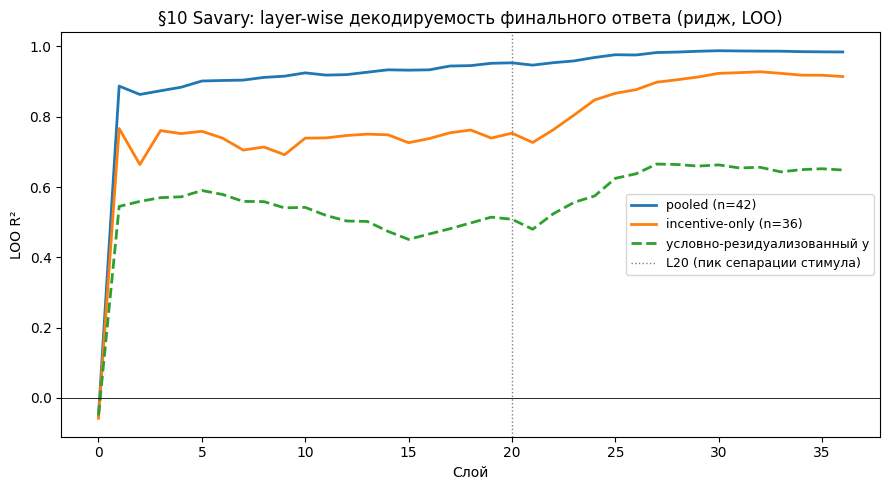

pooled:  L2=0.863 → пик L30=0.988
inc-only: L20=0.753 → L30=0.923
resid:   L4=0.572 → пик L27=0.665


In [29]:
# 10.1 Layer-wise LOO decodability: pooled / incentive-only / residualized
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut, KFold

SAV10 = VIZ[VIZ.exp_short == "Savary"].reset_index(drop=True)
HS10 = np.stack([np.asarray(features_hs[k], dtype=np.float32)
                 for k in SAV10.feature_key], axis=0)
y10 = SAV10["y_cont"].values
inc10 = (SAV10["incentive_condition"].astype(str) != "none").values
y10_resid = SAV10.groupby("incentive_condition", observed=True)["y_cont"].transform(
    lambda s: s - s.mean()).values
print(f"Savary: n={len(SAV10)} (none={int((~inc10).sum())}, incentive={int(inc10.sum())})")
print(f"var(y)={y10.var():.4f}, var(y_resid)={y10_resid.var():.4f} "
      f"(внутри-условная доля: {y10_resid.var()/y10.var():.2f})")

RIDGE_ALPHA10 = 1000.0  # sensitivity: alpha=100 → R²@L20=0.964, alpha=10000 → 0.849

def _loo_pred10(X, yy):
    loo = LeaveOneOut(); pr = np.zeros(len(yy))
    for tr, te in loo.split(X):
        sc = StandardScaler().fit(X[tr])
        pr[te] = Ridge(alpha=RIDGE_ALPHA10).fit(
            sc.transform(X[tr]), yy[tr]).predict(sc.transform(X[te]))
    return pr

def _r2_10(yy, pr):
    return 1 - ((yy - pr) ** 2).sum() / ((yy - yy.mean()) ** 2).sum()

NL10 = HS10.shape[1]
r2_pooled = np.full(NL10, np.nan)
r2_inc = np.full(NL10, np.nan)
r2_resid = np.full(NL10, np.nan)
for L in range(NL10):
    r2_pooled[L] = _r2_10(y10, _loo_pred10(HS10[:, L, :], y10))
    r2_inc[L] = _r2_10(y10[inc10], _loo_pred10(HS10[inc10][:, L, :], y10[inc10]))
    r2_resid[L] = _r2_10(y10_resid, _loo_pred10(HS10[:, L, :], y10_resid))

fig10, ax10 = plt.subplots(figsize=(9, 5))
ax10.plot(r2_pooled, label="pooled (n=42)", lw=2)
ax10.plot(r2_inc, label="incentive-only (n=36)", lw=2)
ax10.plot(r2_resid, label="условно-резидуализованный y", lw=2, ls="--")
ax10.axvline(20, color="grey", ls=":", lw=1, label="L20 (пик сепарации стимула)")
ax10.axhline(0, color="black", lw=0.6)
ax10.set_xlabel("Слой"); ax10.set_ylabel("LOO R²")
ax10.set_title("§10 Savary: layer-wise декодируемость финального ответа (ридж, LOO)")
ax10.legend(fontsize=9); fig10.tight_layout(); plt.show()

L_BEST10 = int(np.nanargmax(r2_pooled))
L_BEST10_RES = int(np.nanargmax(r2_resid))
print(f"pooled:  L2={r2_pooled[2]:.3f} → пик L{L_BEST10}={r2_pooled[L_BEST10]:.3f}")
print(f"inc-only: L20={r2_inc[20]:.3f} → L30={r2_inc[30]:.3f}")
print(f"resid:   L4={r2_resid[4]:.3f} → пик L{L_BEST10_RES}={r2_resid[L_BEST10_RES]:.3f}")

In [30]:
# 10.2 Permutation-нуль (5-fold CV, 200 перестановок) + residuals by condition
_rng10 = np.random.default_rng(0)

def _cv_r2_10(X, yy):
    kf = KFold(5, shuffle=True, random_state=0); pr = np.zeros(len(yy))
    for tr, te in kf.split(X):
        sc = StandardScaler().fit(X[tr])
        pr[te] = Ridge(alpha=RIDGE_ALPHA10).fit(
            sc.transform(X[tr]), yy[tr]).predict(sc.transform(X[te]))
    return _r2_10(yy, pr)

perm_rows = []
for L in (4, 20, L_BEST10, 34):
    obs = _cv_r2_10(HS10[:, L, :], y10)
    null = np.array([_cv_r2_10(HS10[:, L, :], _rng10.permutation(y10))
                     for _ in range(200)])
    perm_rows.append({"layer": L, "obs_CV_R2": obs,
                      "null_95pct": np.percentile(null, 95),
                      "p_perm": (1 + (null >= obs).sum()) / 201})
display(Markdown("**Permutation-нуль (pooled y)**"))
display(pd.DataFrame(perm_rows).round(4))

pr_best = _loo_pred10(HS10[:, L_BEST10, :], y10)
res10 = np.abs(y10 - pr_best)
display(Markdown(
    f"**Pooled LOO |residual| @L{L_BEST10}:** none = {res10[~inc10].mean():.3f} (n=6), "
    f"incentive = {res10[inc10].mean():.3f} (n=36) — у baseline-прогонов ошибка выше "
    f"(меньше обучающих примеров своего региона y)."))

**Permutation-нуль (pooled y)**

,layer,obs_CV_R2,null_95pct,p_perm
0,4,0.8831,0.0415,0.005
1,20,0.9487,0.0018,0.005
2,30,0.9842,0.0035,0.005
3,34,0.9820,-0.0035,0.005


**Pooled LOO |residual| @L30:** none = 0.040 (n=6), incentive = 0.021 (n=36) — у baseline-прогонов ошибка выше (меньше обучающих примеров своего региона y).

## §10 — итог: ответ считывается рано, «кристаллизуется» поздно

1. **Pooled-декодируемость высока уже с ранних слоёв** (LOO R²≈0.86 на L2) и монотонно
   растёт до ≈0.99 на L28–30; permutation p≈0.005 на всех проверенных слоях. Но это
   ожидаемо тривиально: y структурирован условиями, а условия читаются из текста промпта
   (ср. §9.1 — incentive-проба идеальна на всех слоях).
2. **Нетривиальная часть — условно-резидуализованный y** (7% дисперсии, вариация внутри
   incentive-условий): декодируется на R²≈0.55–0.57 уже на L2–L4 и растёт до пика
   **R²≈0.66 на L27–30** (argmax L27=0.665). Т.е. hidden states несут информацию о будущем ответе сверх
   идентичности условия, и максимум этой информации — в поздних слоях.
3. **Профиль ответа смещён позже пика сепарации стимула**: сепарация none/incentive
   пикует на L20 (§2/§9.3), а декодируемость ответа — на L27–30. Согласуется с §5:
   стимул «обрабатывается» в средних слоях, ответ финализируется в поздних.
4. Hassner: проба не определена — y_cont вырожден (P(Yes)=0.998±0.003), поведенческое
   насыщение (§7) делает вопрос «когда читается ответ» бессодержательным.

**Caveats**: n=42 (резидуализованная проба фактически на 7% дисперсии y); group/context
тоже видимы в тексте промпта, поэтому полная каузальная изоляция «ответа» от «условия»
невозможна в этом дизайне; alpha-чувствительность умеренная (R²@L20: 0.96/0.95/0.85
при α=100/1000/10000); exploratory.